# Exploración de datos y componentes principales de los países del mundo
**Métodos Matemáticos Computacionales para Ciencia de Datos** · UNAM, IIMAS · Licenciatura en Ciencia de Datos

De La Cruz Maldonado José Eduardo · López Reyes Jorge · Profesora: Nora Isabel Pérez Quezadas

Este notebook contiene todo el código del reporte `reporte/Proyecto_PCA_Paises.pdf`: el análisis, el
cálculo de los valores de las tablas y la generación de las figuras. Las secciones llevan la misma
numeración que el reporte. Al ejecutarlo se vuelven a crear las carpetas `graficas` y `resultados`.

## Preparación
Paquetes, carpetas de salida, estilo de las gráficas y nombres en español de las variables.

In [1]:
import json
import sys
from itertools import combinations
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg")                       # genera los PNG sin abrir ventanas en cualquier sistema
import matplotlib.pyplot as plt
from matplotlib.colors import SymLogNorm
import seaborn as sns
from sklearn.decomposition import PCA
import warnings
warnings.filterwarnings("ignore", category=matplotlib.MatplotlibDeprecationWarning)

if hasattr(sys.stdout, "reconfigure"):       # acentos correctos también en la consola de Windows
    sys.stdout.reconfigure(encoding="utf-8", errors="replace")

# Carpeta del proyecto: la del archivo si se ejecuta como programa, o la actual si es el notebook
BASE = Path(__file__).resolve().parent if "__file__" in globals() else Path.cwd()
EN_NOTEBOOK = "get_ipython" in globals()
FIG = BASE / "graficas"
RES = BASE / "resultados"
FIG.mkdir(exist_ok=True)
RES.mkdir(exist_ok=True)

C1, C2 = "#2f4b6e", "#a0522d"               # azul y siena de todas las gráficas
plt.rcParams.update({
    "font.family": "serif", "font.serif": ["DejaVu Serif"], "font.size": 8,
    "axes.titlesize": 8.5, "axes.labelsize": 8, "axes.spines.top": False,
    "axes.spines.right": False, "legend.fontsize": 7, "savefig.dpi": 200,
    "savefig.bbox": "tight", "figure.dpi": 100, "mathtext.fontset": "dejavuserif",
})

NOMBRES = {
    "Region": "Región", "Population": "Población", "Area (sq. mi.)": "Superficie",
    "Pop. Density (per sq. mi.)": "Densidad de población",
    "Coastline (coast/area ratio)": "Costa / área", "Net migration": "Migración neta",
    "Infant mortality (per 1000 births)": "Mortalidad infantil",
    "GDP ($ per capita)": "PIB per cápita", "Literacy (%)": "Alfabetización",
    "Phones (per 1000)": "Teléfonos", "Arable (%)": "Tierra cultivable",
    "Crops (%)": "Cultivos permanentes", "Other (%)": "Otros usos del suelo",
    "Climate": "Clima", "Birthrate": "Natalidad", "Deathrate": "Mortalidad",
    "Agriculture": "Agricultura", "Industry": "Industria", "Service": "Servicios",
}
UNIDADES = {
    "Population": "habitantes", "Area (sq. mi.)": "millas cuadradas",
    "Pop. Density (per sq. mi.)": "hab. por milla cuadrada",
    "Coastline (coast/area ratio)": "razón costa / área", "Net migration": "por cada 1000 hab.",
    "Infant mortality (per 1000 births)": "por cada 1000 nacimientos",
    "GDP ($ per capita)": "USD por habitante", "Literacy (%)": "%",
    "Phones (per 1000)": "líneas por cada 1000 hab.", "Arable (%)": "% de la superficie",
    "Crops (%)": "% de la superficie", "Other (%)": "% de la superficie",
    "Birthrate": "por cada 1000 hab.", "Deathrate": "por cada 1000 hab.",
    "Agriculture": "fracción del PIB", "Industry": "fracción del PIB", "Service": "fracción del PIB",
}
GRUPO = {
    "SUB-SAHARAN AFRICA": "África", "NORTHERN AFRICA": "África",
    "LATIN AMER. & CARIB": "América", "NORTHERN AMERICA": "América",
    "ASIA (EX. NEAR EAST)": "Asia y Cercano Oriente", "NEAR EAST": "Asia y Cercano Oriente",
    "WESTERN EUROPE": "Europa", "EASTERN EUROPE": "Europa", "BALTICS": "Europa",
    "C.W. OF IND. STATES": "CEI", "OCEANIA": "Oceanía",
}
COLORES = {"África": "#c0392b", "América": "#1b6ca8", "Asia y Cercano Oriente": "#2e8b57",
           "Europa": "#8e44ad", "CEI": "#d68910", "Oceanía": "#555555"}

RESULTADOS = {}                              # números que usa el reporte


def guardar(fig, nombre):
    """Guarda la figura en la carpeta de gráficas y, en el notebook, también la muestra."""
    fig.savefig(FIG / nombre)
    plt.close(fig)
    if EN_NOTEBOOK:
        from IPython.display import Image, display
        display(Image(filename=str(FIG / nombre), width=min(760, int(fig.get_figwidth() * 115))))


def mostrar(tabla, titulo):
    """Muestra una tabla con su título (con formato en el notebook, como texto en la consola)."""
    if EN_NOTEBOOK:
        from IPython.display import Markdown, display
        display(Markdown(f"**{titulo}**"))
        display(tabla)
    else:
        print(f"\n{titulo}")
        print(tabla.to_string())


def iqr_atipicos(x):
    """Valores fuera de [Q1 - 1.5 RIC, Q3 + 1.5 RIC]."""
    x = x.dropna()
    q1, q3 = x.quantile([0.25, 0.75])
    ric = q3 - q1
    return x[(x < q1 - 1.5 * ric) | (x > q3 + 1.5 * ric)].sort_values(
        key=lambda s: (s - x.median()).abs(), ascending=False)

## 1.3 Lectura de los datos
El CSV de Kaggle usa coma decimal y trae espacios al final de los nombres de país y de región, así que
se indica `decimal=","` y se limpian los textos. El país queda como índice. También se cuentan los países
de cada región y de cada tipo de clima (Figura de las variables categóricas).

filas y columnas: (227, 19)


**Primeras filas**

,Region,Population,Area (sq. mi.),Pop. Density (per sq. mi.),Coastline (coast/area ratio),Net migration,Infant mortality (per 1000 births),GDP ($ per capita),Literacy (%),Phones (per 1000),Arable (%),Crops (%),Other (%),Climate,Birthrate,Deathrate,Agriculture,Industry,Service
Country,,,,,,,,,,,,,,,,,,,
Afghanistan,ASIA (EX. NEAR EAST),31056997,647500,48.0,0.00,23.06,163.07,700.0,36.0,3.2,12.13,0.22,87.65,1.0,46.60,20.34,0.380,0.240,0.380
Albania,EASTERN EUROPE,3581655,28748,124.6,1.26,-4.93,21.52,4500.0,86.5,71.2,21.09,4.42,74.49,3.0,15.11,5.22,0.232,0.188,0.579
Algeria,NORTHERN AFRICA,32930091,2381740,13.8,0.04,-0.39,31.00,6000.0,70.0,78.1,3.22,0.25,96.53,1.0,17.14,4.61,0.101,0.600,0.298
American Samoa,OCEANIA,57794,199,290.4,58.29,-20.71,9.27,8000.0,97.0,259.5,10.00,15.00,75.00,2.0,22.46,3.27,NaN,NaN,NaN
Andorra,WESTERN EUROPE,71201,468,152.1,0.00,6.60,4.05,19000.0,100.0,497.2,2.22,0.00,97.78,3.0,8.71,6.25,NaN,NaN,NaN


**Tipo de dato y vacíos por columna**

,tipo,vacíos
Region,str,0
Population,int64,0
Area (sq. mi.),int64,0
Pop. Density (per sq. mi.),float64,0
Coastline (coast/area ratio),float64,0
Net migration,float64,3
Infant mortality (per 1000 births),float64,3
GDP ($ per capita),float64,1
Literacy (%),float64,18
Phones (per 1000),float64,4


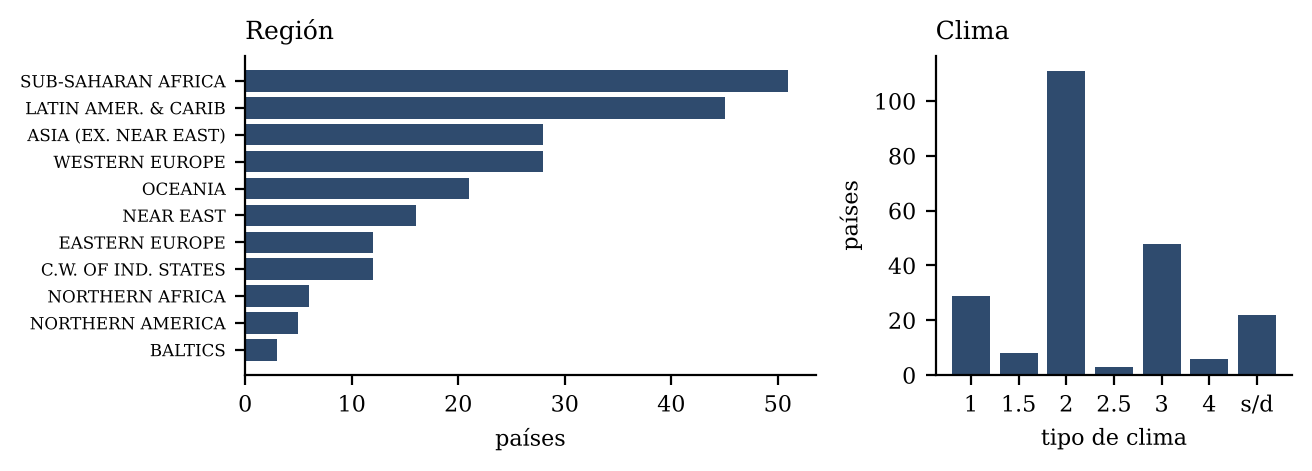

In [2]:
raw = pd.read_csv(BASE / "datos" / "countries_of_the_world.csv", decimal=",")
raw.columns = [c.strip() for c in raw.columns]
raw["Country"] = raw["Country"].str.strip()
raw["Region"] = raw["Region"].str.strip()
raw = raw.set_index("Country")
print("filas y columnas:", raw.shape)
mostrar(raw.head(), "Primeras filas")
mostrar(pd.DataFrame({"tipo": raw.dtypes.astype(str), "vacíos": raw.isna().sum()}), "Tipo de dato y vacíos por columna")

RESULTADOS["n_paises"], RESULTADOS["n_columnas"] = raw.shape[0], raw.shape[1]

# Figura 1: variables categóricas
reg = raw["Region"].value_counts()
clima = raw["Climate"].value_counts().sort_index()
etq_clima = [f"{c:g}" for c in clima.index] + ["s/d"]
val_clima = list(clima.values) + [int(raw["Climate"].isna().sum())]
fig, (a, b) = plt.subplots(1, 2, figsize=(6.6, 2.4), gridspec_kw={"width_ratios": [1.6, 1]})
a.barh(reg.index[::-1], reg.values[::-1], color=C1)
a.set_xlabel("países"); a.set_title("Región", loc="left", fontsize=9)
a.tick_params(axis="y", labelsize=6)
b.bar(etq_clima, val_clima, color=C1)
b.set_xlabel("tipo de clima"); b.set_ylabel("países"); b.set_title("Clima", loc="left", fontsize=9)
fig.tight_layout(); guardar(fig, "fig_categoricas.png")
RESULTADOS["regiones"] = {k: int(v) for k, v in reg.items()}
RESULTADOS["clima"] = {e: int(v) for e, v in zip(etq_clima, val_clima)}

## 2.1 Valores faltantes
Porcentaje de países sin dato en cada columna.

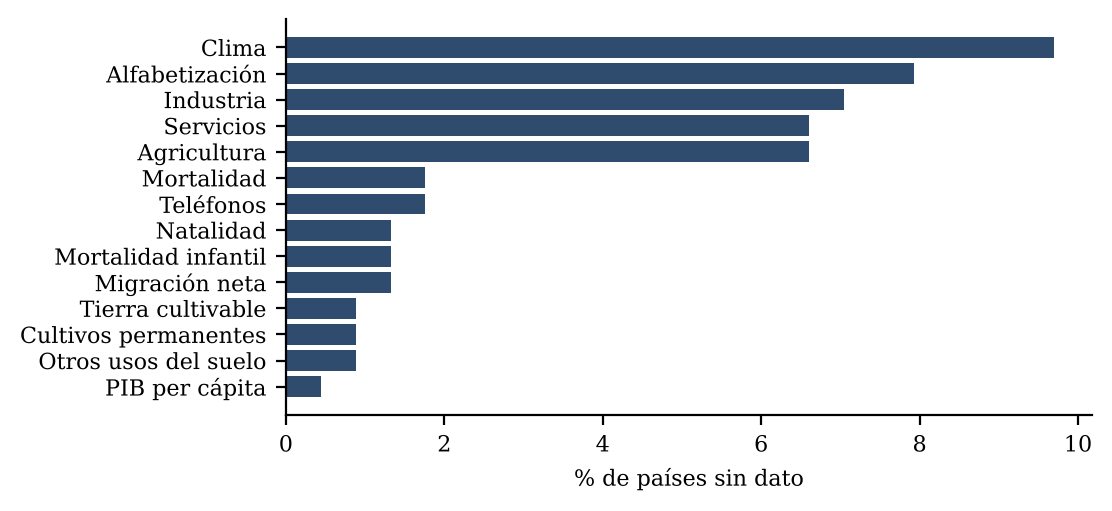

In [3]:
nulos = raw.isna().sum()
nulos = (100 * nulos[nulos > 0] / len(raw)).sort_values()
fig, ax = plt.subplots(figsize=(5.6, 2.6))
ax.barh([NOMBRES[v] for v in nulos.index], nulos.values, color=C1)
ax.set_xlabel("% de países sin dato")
fig.tight_layout(); guardar(fig, "fig_faltantes.png")
RESULTADOS["faltantes"] = {v: [int(raw[v].isna().sum()), float(p)] for v, p in nulos[::-1].items()}

## 2.2 Variables descartadas
Comprobaciones que justifican qué columnas no entran al PCA: los tres usos del suelo suman 100, los tres
sectores del PIB suman 1 (por eso sobra una de cada grupo) y población y superficie son muy asimétricas.

In [4]:
suelo = raw[["Arable (%)", "Crops (%)", "Other (%)"]].dropna().sum(axis=1)
sectores = raw[["Agriculture", "Industry", "Service"]].dropna().sum(axis=1)
RESULTADOS["suma_suelo"] = [float(suelo.min()), float(suelo.max())]
RESULTADOS["suma_sectores"] = [float(sectores.min()), float(sectores.max())]
RESULTADOS["corr_industria"] = [float(raw["Industry"].corr(raw["Agriculture"])),
                                float(raw["Industry"].corr(raw["Service"]))]
RESULTADOS["asim_tamano"] = [float(raw["Population"].skew()), float(raw["Area (sq. mi.)"].skew())]
print("suma de los tres usos del suelo: de %.2f a %.2f" % tuple(RESULTADOS["suma_suelo"]))
print("suma de los tres sectores del PIB: de %.3f a %.3f" % tuple(RESULTADOS["suma_sectores"]))
print("correlación de industria con agricultura y con servicios: %.2f y %.2f" % tuple(RESULTADOS["corr_industria"]))
print("asimetría de población y de superficie: %.1f y %.1f" % tuple(RESULTADOS["asim_tamano"]))

suma de los tres usos del suelo: de 99.88 a 100.01
suma de los tres sectores del PIB: de 0.906 a 1.010
correlación de industria con agricultura y con servicios: -0.32 y -0.54
asimetría de población y de superficie: 9.2 y 6.0


## 2.3 Países eliminados y valores imputados
Se eligen las 13 variables del estudio y se cuenta cuántas le faltan a cada país. Los países con cuatro o
más vacíos (más del 30 % de sus variables) se eliminan: estimar tantos valores sería inventar casi un
tercio del país.

In [5]:
VARS = ["Pop. Density (per sq. mi.)", "Coastline (coast/area ratio)", "Net migration",
        "Infant mortality (per 1000 births)", "GDP ($ per capita)", "Literacy (%)",
        "Phones (per 1000)", "Arable (%)", "Crops (%)", "Birthrate", "Deathrate",
        "Agriculture", "Service"]
datos = raw[VARS + ["Region"]].copy()
faltan = datos[VARS].isna().sum(axis=1)
eliminados = datos.index[faltan >= 4].tolist()      # más del 30 % de las variables sin dato
datos = datos[faltan < 4].copy()
observados = datos[VARS].copy()                     # valores realmente observados (con sus vacíos)
print("países según el número de variables sin dato:")
print(faltan.value_counts().sort_index().to_string())
print("eliminados:", eliminados, "| quedan:", len(datos))
RESULTADOS["faltan_por_pais"] = {int(n): int(c) for n, c in faltan.value_counts().sort_index().items()}
RESULTADOS["faltan_eliminados"] = {pais: int(faltan[pais]) for pais in eliminados}

países según el número de variables sin dato:
0    194
1     15
2      9
3      6
5      1
6      1
8      1
eliminados: ['Mayotte', 'Wallis and Futuna', 'Western Sahara'] | quedan: 224


### Interpolación en lugar de la mediana
Cada vacío se estima con el valor que el propio país tiene en otra variable (la *predictora*):

1. **Predictora.** Es la variable con mayor correlación de Pearson (en valor absoluto) con la variable
   que tiene el vacío, calculada con los países que tienen ambos datos. Si al país también le falta
   esa variable, se usa la siguiente más correlacionada.
2. **Nodos.** Los países con dato en ambas variables se ordenan por la predictora y se dividen en 8
   grupos del mismo tamaño; cada grupo aporta un nodo (mediana de la predictora, mediana de la variable).
3. **Interpolación lineal.** El vacío se estima con la recta que une los dos nodos entre los que cae
   el valor de la predictora del país.

**Variable predictora de cada variable con vacíos**

,vacíos,predictora,|r|
Literacy (%),16,Birthrate,0.791
Service,13,Phones (per 1000),0.684
Agriculture,12,Infant mortality (per 1000 births),0.709
Phones (per 1000),3,GDP ($ per capita),0.834
Deathrate,2,Infant mortality (per 1000 births),0.658
Net migration,1,GDP ($ per capita),0.389
Infant mortality (per 1000 births),1,Birthrate,0.847
Arable (%),1,Birthrate,0.187
Crops (%),1,Net migration,0.348
Birthrate,1,Infant mortality (per 1000 births),0.847


**Valores imputados**

,pais,variable,predictora,valor_predictora,valor_imputado
0,Bosnia & Herzegovina,Literacy (%),Birthrate,8.77,99.000
1,Faroe Islands,Literacy (%),Birthrate,14.05,96.886
2,Gaza Strip,Literacy (%),Birthrate,39.45,54.501
3,Gibraltar,Literacy (%),Birthrate,10.74,98.424
4,Greenland,Literacy (%),Birthrate,15.93,95.173
5,Guernsey,Literacy (%),Birthrate,8.81,99.000
6,Isle of Man,Literacy (%),Birthrate,11.05,98.296
7,Jersey,Literacy (%),Birthrate,9.30,99.000
8,Kiribati,Literacy (%),Birthrate,30.65,70.815
9,Macedonia,Literacy (%),Birthrate,12.02,97.849


vacíos restantes: 0


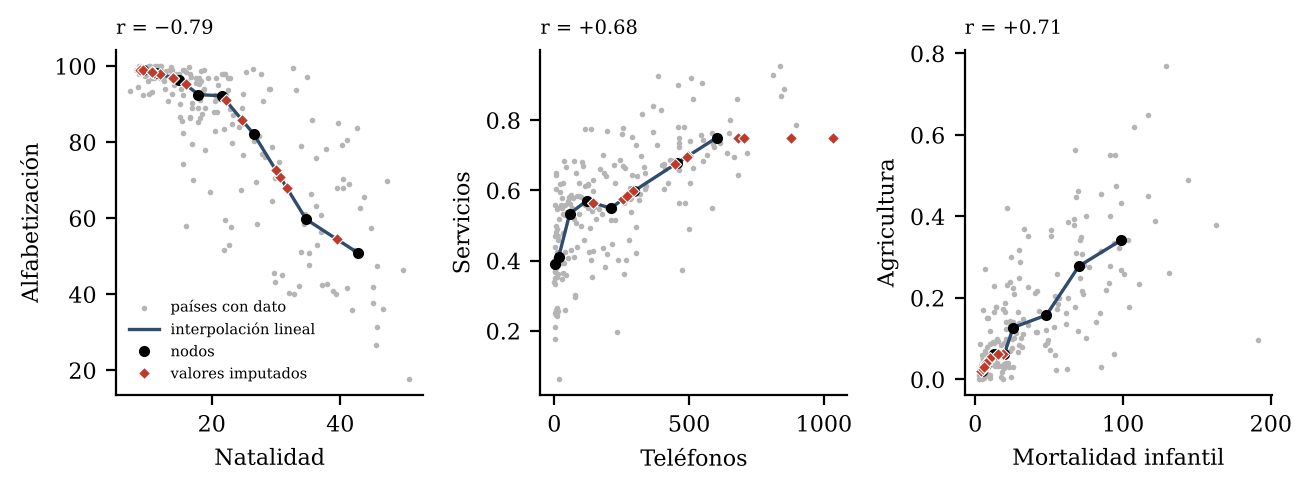

In [6]:
N_NODOS = 8


def nodos(x, y, m=N_NODOS):
    """Un nodo por cada grupo de países ordenados por x: (mediana de x, mediana de y)."""
    grupo = pd.qcut(x.rank(method="first"), m, labels=False)
    g = pd.DataFrame({"x": x, "y": y}).groupby(grupo).median().sort_values("x")
    g = g.groupby("x", as_index=False).mean()                   # si dos grupos comparten x, se promedian
    return g["x"].to_numpy(float), g["y"].to_numpy(float)


def interpolar(xn, yn, x):
    """Interpolación lineal entre nodos. Fuera de los nodos no se extrapola: se usa el nodo del extremo."""
    return np.interp(np.clip(np.atleast_1d(np.asarray(x, float)), xn[0], xn[-1]), xn, yn)


corr_obs = observados.corr(method="pearson")                    # con los países que tienen ambos datos
con_vacios = observados.isna().sum()
con_vacios = con_vacios[con_vacios > 0].sort_values(ascending=False)
orden_pred = {v: corr_obs[v].drop(v).abs().sort_values(ascending=False) for v in con_vacios.index}
mostrar(pd.DataFrame({"vacíos": con_vacios, "predictora": [orden_pred[v].index[0] for v in con_vacios.index],
                      "|r|": [orden_pred[v].iloc[0] for v in con_vacios.index]}).round(3),
        "Variable predictora de cada variable con vacíos")

imputaciones = []
for v in con_vacios.index:
    for pais in observados.index[observados[v].isna()]:
        x = next(c for c in orden_pred[v].index if pd.notna(observados.loc[pais, c]))
        ambos = observados[[x, v]].dropna()
        xn, yn = nodos(ambos[x], ambos[v])
        valor = float(np.clip(interpolar(xn, yn, observados.loc[pais, x])[0], ambos[v].min(), ambos[v].max()))
        datos.loc[pais, v] = valor
        imputaciones.append({"pais": pais, "variable": v, "predictora": x,
                             "valor_predictora": observados.loc[pais, x], "valor_imputado": valor})
imputaciones = pd.DataFrame(imputaciones)
imputaciones.to_csv(RES / "valores_imputados.csv", index=False, encoding="utf-8")
mostrar(imputaciones.round(3), "Valores imputados")
print("vacíos restantes:", int(datos[VARS].isna().sum().sum()))

# Figura: nodos e interpolación lineal de las tres variables con más vacíos
fig, axes = plt.subplots(1, 3, figsize=(6.6, 2.5))
for ax, v in zip(axes, con_vacios.index[:3]):
    x = orden_pred[v].index[0]
    ambos = observados[[x, v]].dropna()
    xn, yn = nodos(ambos[x], ambos[v])
    xs = np.linspace(xn[0], xn[-1], 300)
    ax.scatter(ambos[x], ambos[v], s=4, color="#b5b5b5", linewidths=0, label="países con dato")
    ax.plot(xs, interpolar(xn, yn, xs), color=C1, lw=1.2, label="interpolación lineal")
    ax.plot(xn, yn, "o", color="black", ms=3, label="nodos")
    imp_v = imputaciones[(imputaciones["variable"] == v) & (imputaciones["predictora"] == x)]
    ax.plot(imp_v["valor_predictora"], imp_v["valor_imputado"], "D", color="#c0392b", ms=3.2, mec="white",
            mew=.4, label="valores imputados")
    ax.set_xlabel(NOMBRES[x]); ax.set_ylabel(NOMBRES[v])
    ax.set_title(f"r = {corr_obs.loc[x, v]:+.2f}".replace("-", "−"), loc="left", fontsize=7)
axes[0].legend(frameon=False, fontsize=5.3)
fig.tight_layout(); guardar(fig, "fig_imputacion.png")
RESULTADOS["imputacion"] = {v: {"n": int(con_vacios[v]), "predictora": orden_pred[v].index[0],
                                "r": float(corr_obs.loc[orden_pred[v].index[0], v])} for v in con_vacios.index}
RESULTADOS["imputacion_otras"] = int(sum(f["predictora"] != orden_pred[f["variable"]].index[0]
                                         for _, f in imputaciones.iterrows()))
RESULTADOS["n_nodos"] = N_NODOS

imputados = raw.loc[datos.index, VARS].isna().sum()
RESULTADOS["eliminados"] = eliminados
RESULTADOS["n_depurados"] = len(datos)
RESULTADOS["imputados"] = {v: int(n) for v, n in imputados.sort_values(ascending=False).items() if n > 0}

## 2.4 Transformación de variables muy asimétricas
Se calcula el coeficiente de asimetría (`skew`) de cada variable y se aplica `log10(x + 1)` a las que
tienen |asimetría| ≥ 2. La figura compara la distribución antes y después.

**Coeficiente de asimetría**

,antes,después
Pop. Density (per sq. mi.),8.23,0.32
Coastline (coast/area ratio),8.19,1.14
Net migration,0.14,0.14
Infant mortality (per 1000 births),1.45,1.45
GDP ($ per capita),1.36,1.36
Literacy (%),-1.27,-1.27
Phones (per 1000),1.00,1.00
Arable (%),1.33,1.33
Crops (%),3.32,0.88
Birthrate,0.73,0.73


variables transformadas: ['Pop. Density (per sq. mi.)', 'Coastline (coast/area ratio)', 'Crops (%)']


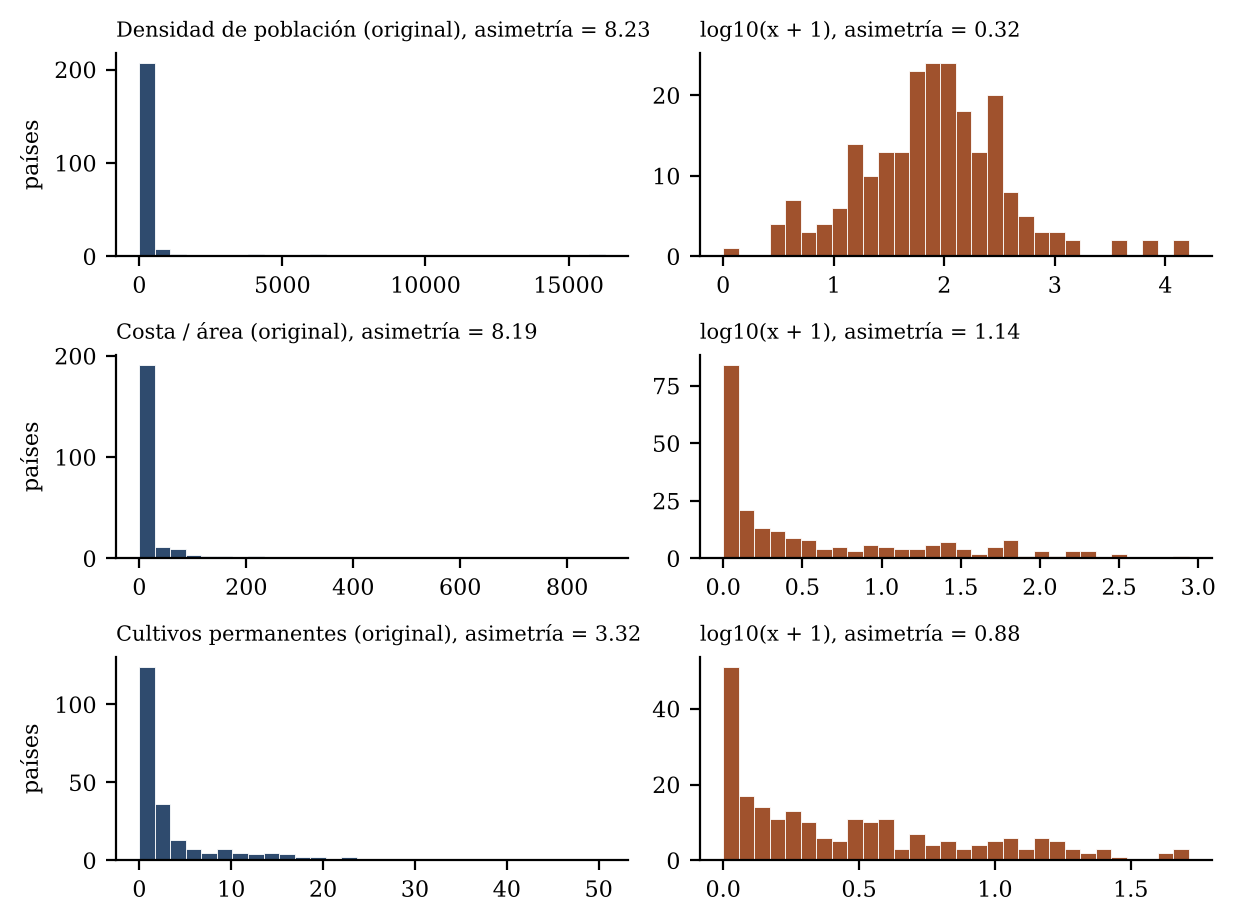

In [7]:
asim_antes = datos[VARS].skew()
a_log = asim_antes[asim_antes.abs() >= 2].index.tolist()
trans = datos.copy()
for v in a_log:
    trans[v] = np.log10(trans[v] + 1)
asim_despues = trans[VARS].skew()
mostrar(pd.DataFrame({"antes": asim_antes, "después": asim_despues}).round(2), "Coeficiente de asimetría")
print("variables transformadas:", a_log)

RESULTADOS["a_log"] = a_log
RESULTADOS["asim_log"] = {v: [float(asim_antes[v]), float(asim_despues[v])] for v in a_log}

fig, axes = plt.subplots(len(a_log), 2, figsize=(6.2, 1.55 * len(a_log)))
for fila, v in zip(axes, a_log):
    fila[0].hist(datos[v], bins=30, color=C1, edgecolor="white", linewidth=.3)
    fila[0].set_title(f"{NOMBRES[v]} (original), asimetría = {asim_antes[v]:.2f}", loc="left", fontsize=7.5)
    fila[0].set_ylabel("países")
    fila[1].hist(trans[v], bins=30, color=C2, edgecolor="white", linewidth=.3)
    fila[1].set_title(f"log10(x + 1), asimetría = {asim_despues[v]:.2f}", loc="left", fontsize=7.5)
fig.tight_layout(); guardar(fig, "fig_log.png")

## 3.1 Gráficas de cada característica
Histograma (con la media y la mediana) y diagrama de caja de cada variable numérica, con los datos
originales. De paso se guardan las estadísticas que aparecen en los pies de figura del reporte.

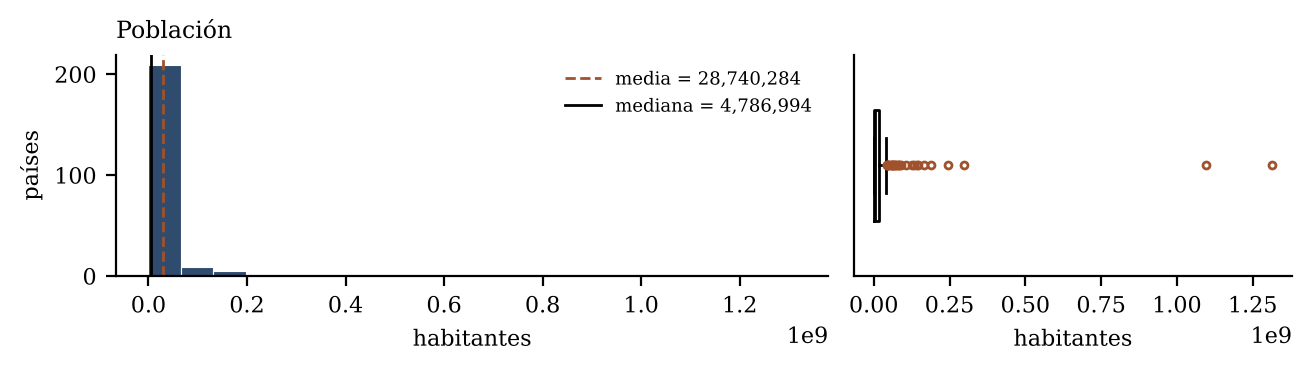

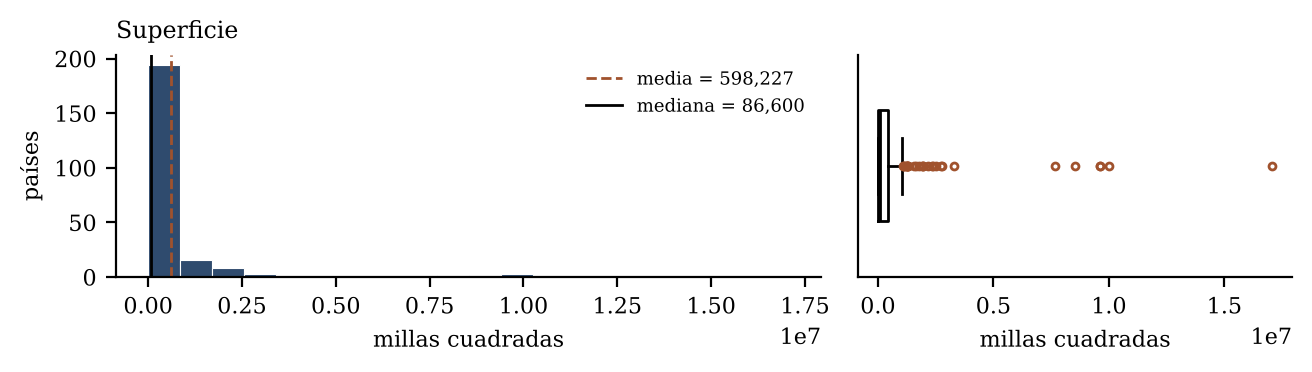

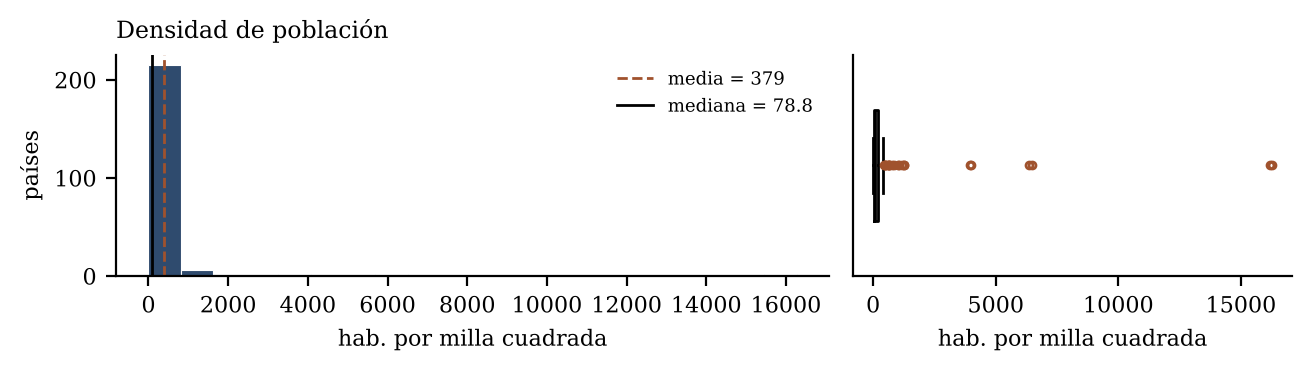

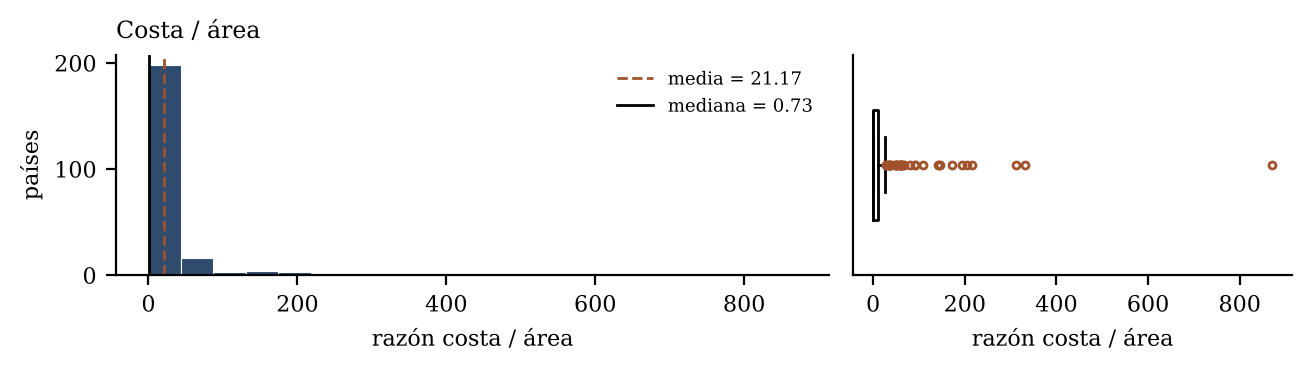

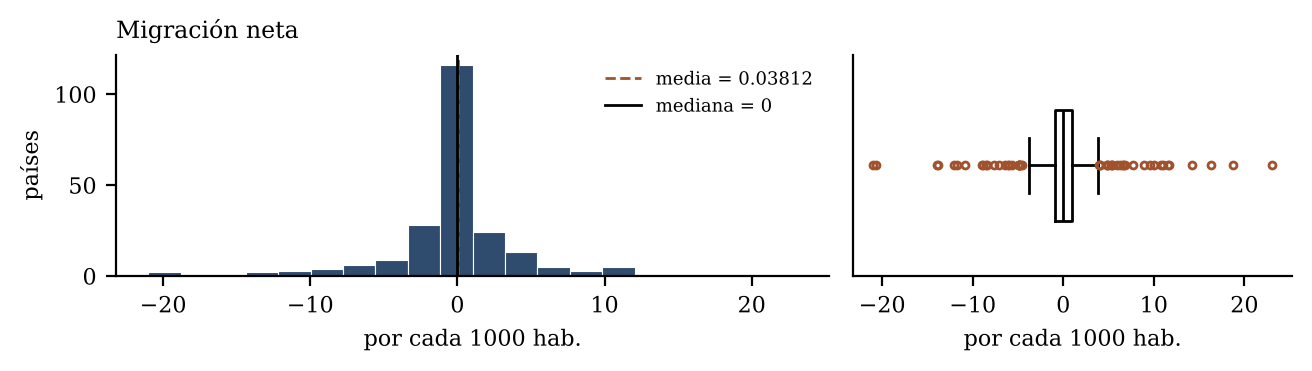

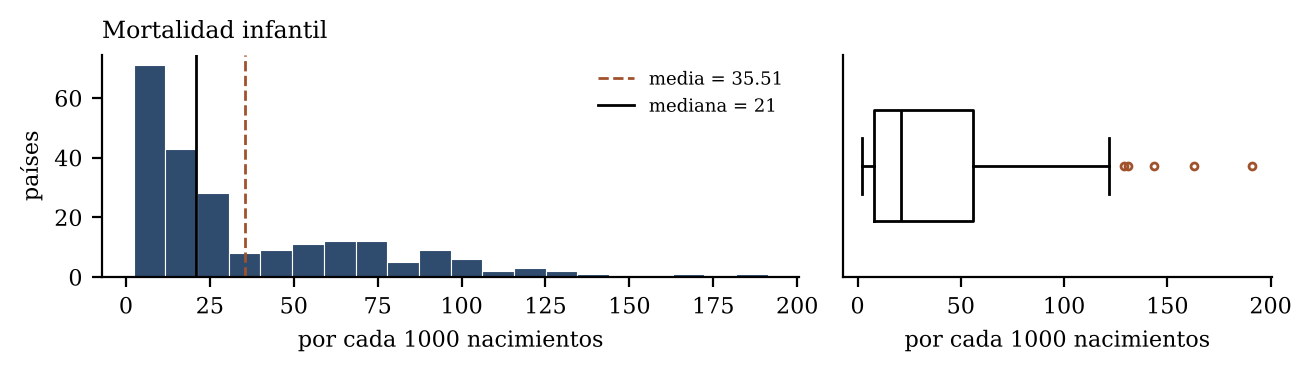

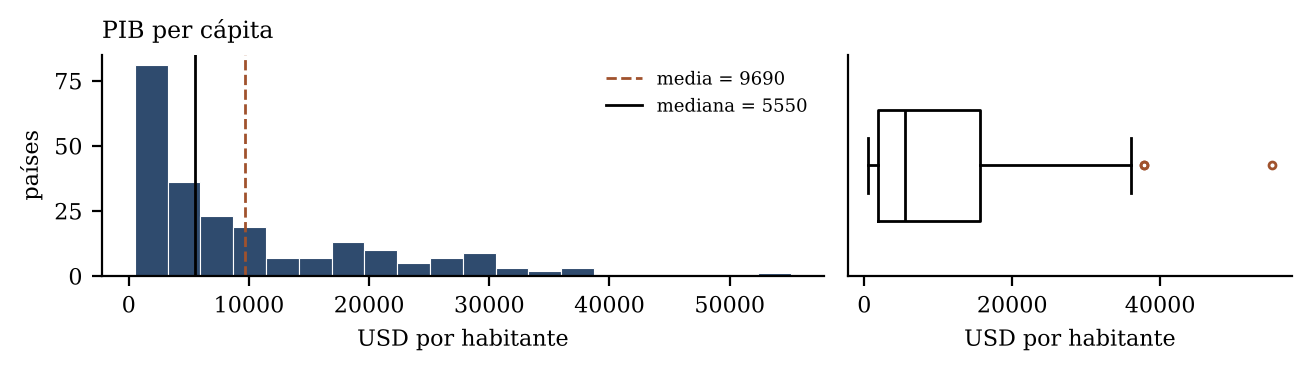

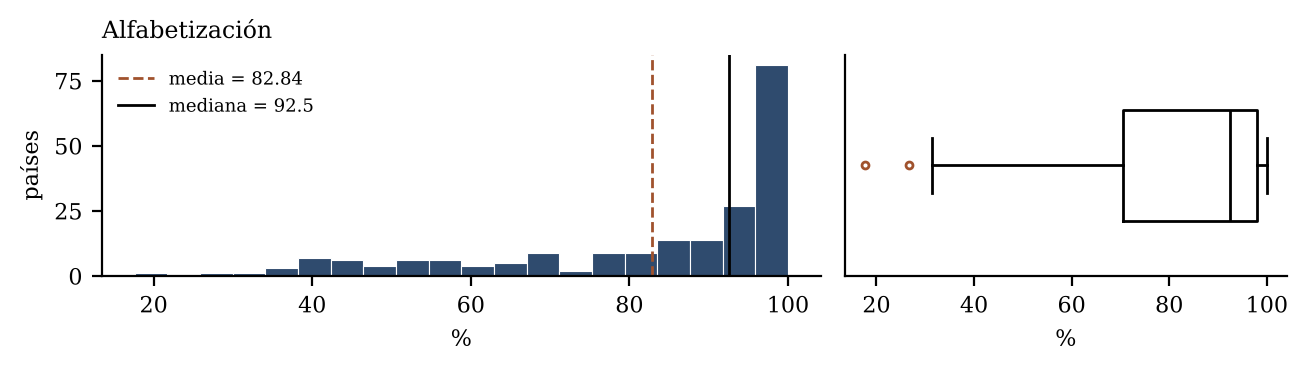

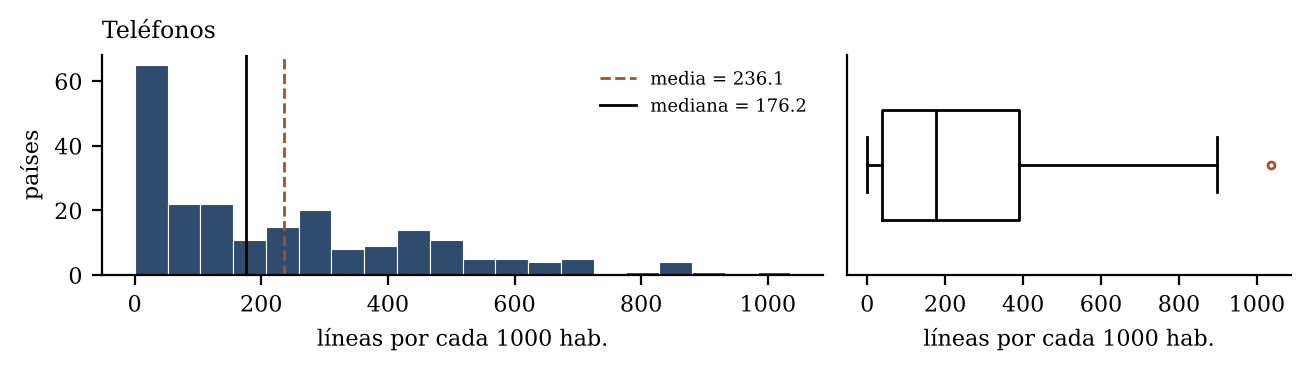

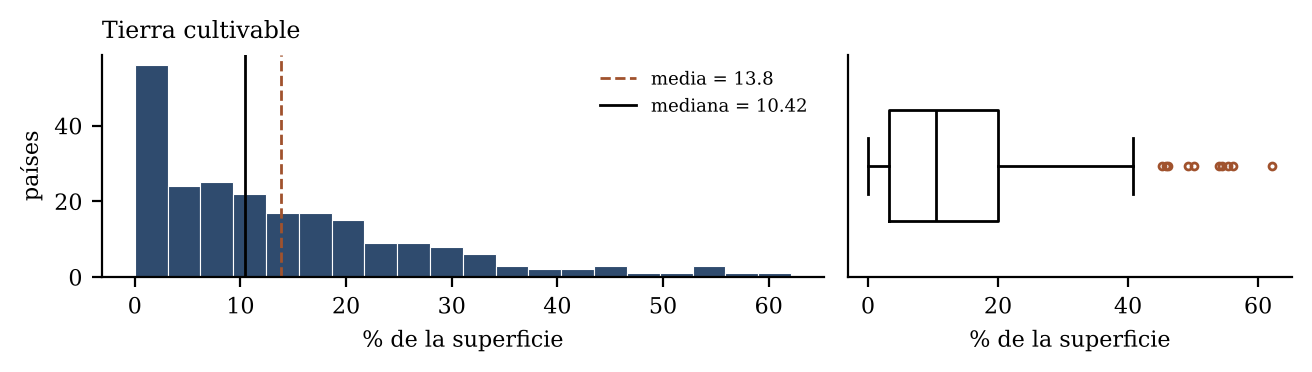

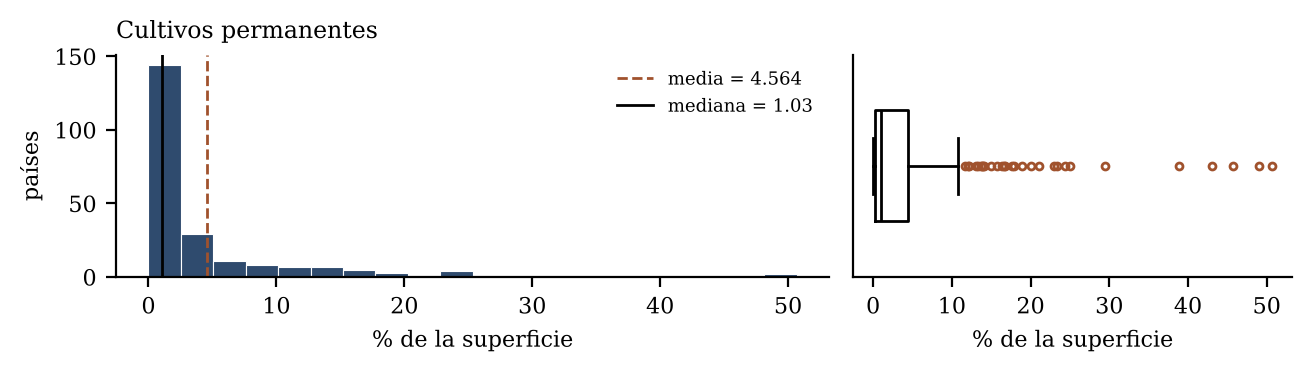

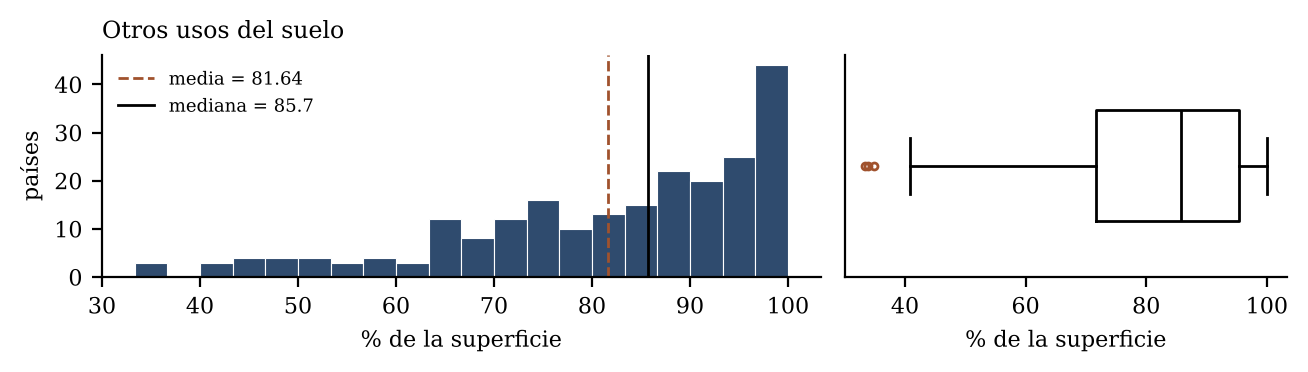

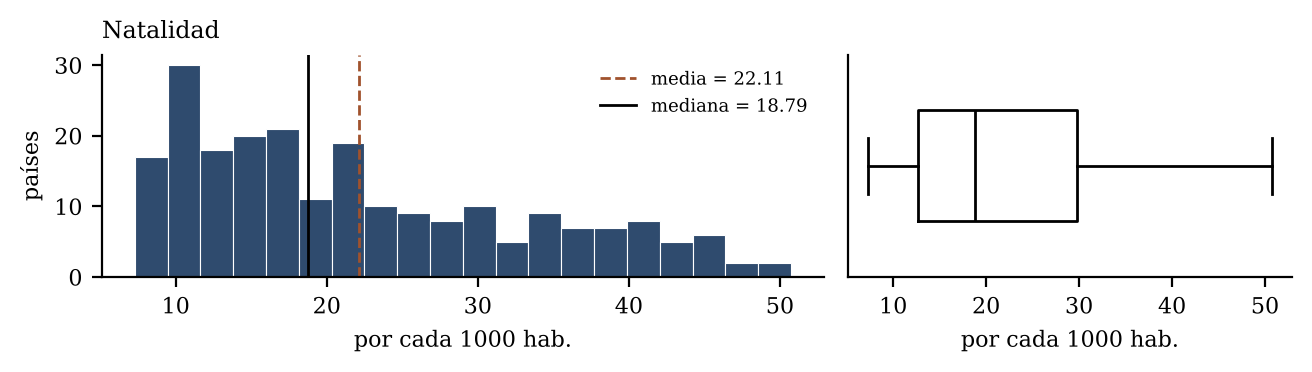

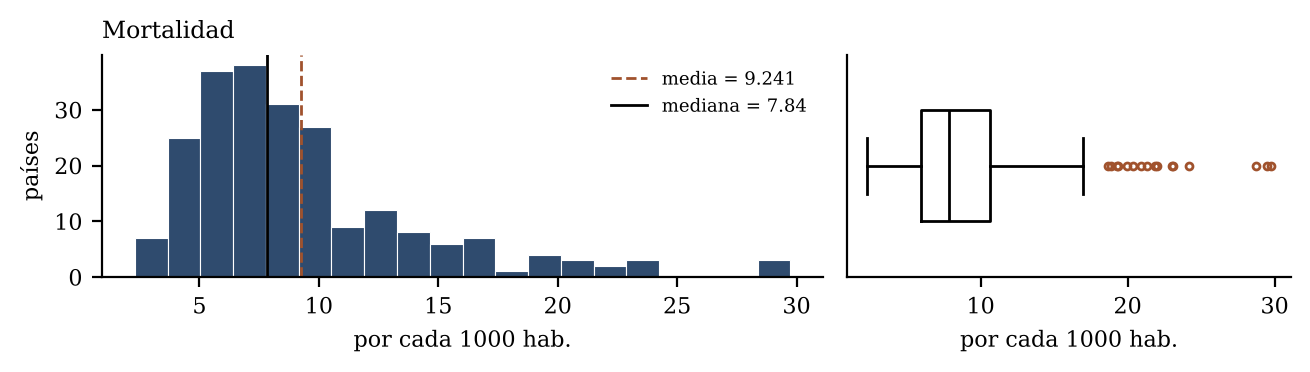

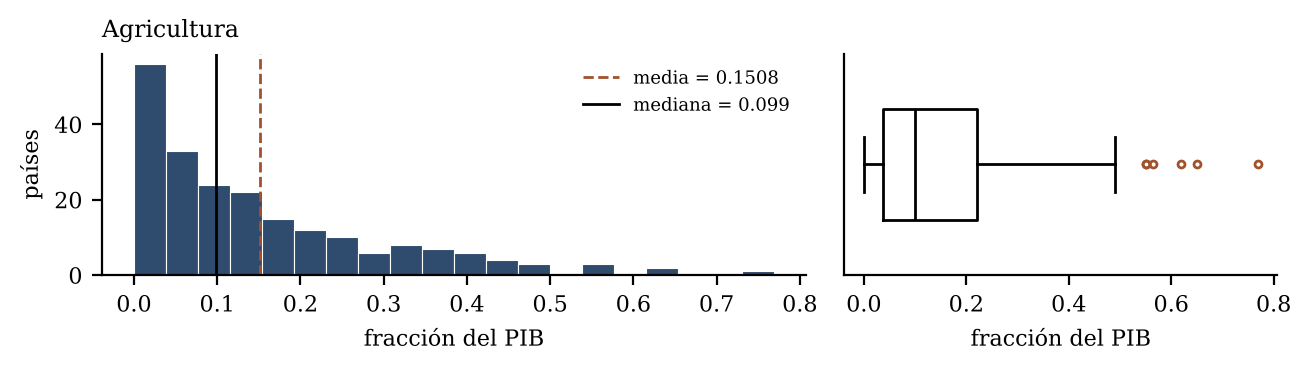

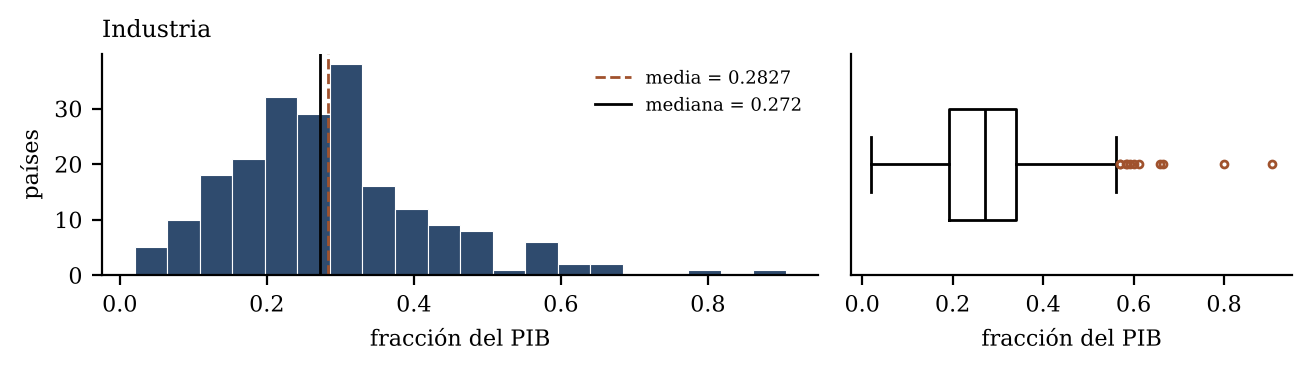

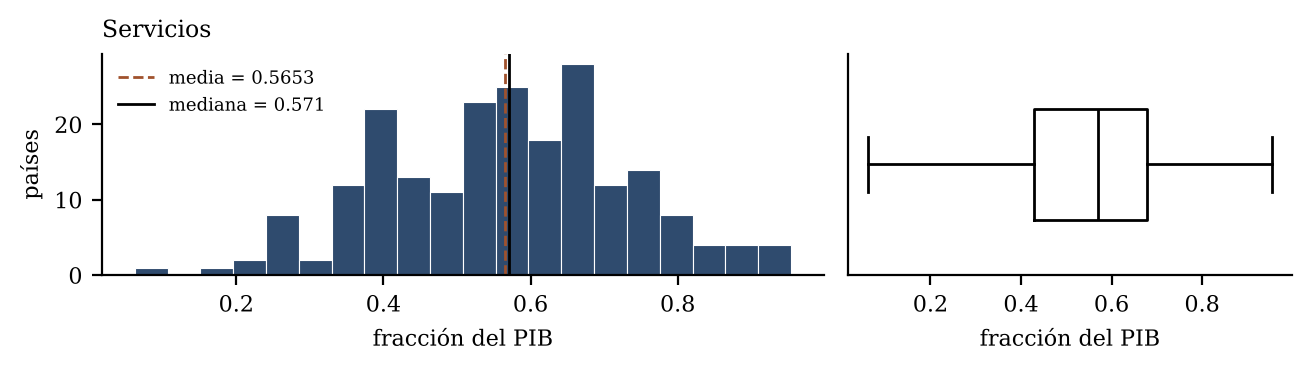

**Estadísticas de cada variable (datos originales)**

,n,nulos,media,mediana,asim,atip,min,max,pais_max
nombre,,,,,,,,,
Población,227,0,28740284.37,4786994.00,9.20,28,7026.00,1.313974e+09,China
Superficie,227,0,598226.96,86600.00,5.96,28,2.00,1.707520e+07,Russia
Densidad de población,227,0,379.05,78.80,8.28,21,0.00,1.627150e+04,Monaco
Costa / área,227,0,21.17,0.73,8.22,37,0.00,8.706600e+02,"Micronesia, Fed. St."
Migración neta,224,3,0.04,0.00,0.13,50,-20.99,2.306000e+01,Afghanistan
Mortalidad infantil,224,3,35.51,21.00,1.43,5,2.29,1.911900e+02,Angola
PIB per cápita,226,1,9689.82,5550.00,1.38,3,500.00,5.510000e+04,Luxembourg
Alfabetización,209,18,82.84,92.50,-1.22,2,17.60,1.000000e+02,Andorra
Teléfonos,223,4,236.06,176.20,1.02,1,0.20,1.035600e+03,Monaco


In [8]:
NUMERICAS = [c for c in raw.columns if c not in ("Region", "Climate")]


def cifra(v):
    """Cifra completa con separador de miles para valores grandes (población, superficie)."""
    return f"{v:,.0f}" if abs(v) >= 1e4 else f"{v:.4g}"


def hist_box(x, titulo, unidad, ruta):
    x = x.dropna()
    fig, (a, b) = plt.subplots(1, 2, figsize=(6.6, 1.9),
                               gridspec_kw={"width_ratios": [2.6, 1.6]})
    a.hist(x, bins=20, color=C1, edgecolor="white", linewidth=.4)
    a.axvline(x.mean(), color=C2, ls="--", lw=1, label=f"media = {cifra(x.mean())}")
    a.axvline(x.median(), color="black", lw=1, label=f"mediana = {cifra(x.median())}")
    a.set_xlabel(unidad); a.set_ylabel("países"); a.set_title(titulo, loc="left", fontsize=8.5)
    a.legend(frameon=False, fontsize=6.5)
    b.boxplot(x, vert=False, widths=.5, medianprops=dict(color="black"),
              flierprops=dict(marker="o", ms=2.5, mfc="none", mec=C2))
    b.set_yticks([]); b.set_xlabel(unidad)
    fig.tight_layout(); guardar(fig, ruta.name)


estad = []
for i, v in enumerate(NUMERICAS):
    hist_box(raw[v], NOMBRES[v], UNIDADES[v], FIG / f"hb_{i:02d}.png")
    x = raw[v].dropna()
    estad.append({"var": v, "nombre": NOMBRES[v], "archivo": f"hb_{i:02d}.png", "n": int(x.size),
                  "nulos": int(raw[v].isna().sum()), "media": x.mean(), "mediana": x.median(),
                  "asim": x.skew(), "atip": int(len(iqr_atipicos(x))),
                  "min": x.min(), "max": x.max(), "pais_max": x.idxmax()})
estad = pd.DataFrame(estad)
mostrar(estad.drop(columns=["archivo", "var"]).set_index("nombre").round(2), "Estadísticas de cada variable (datos originales)")
estad.to_csv(RES / "estadisticas_por_variable.csv", index=False, encoding="utf-8")
RESULTADOS["ceros_migracion"] = int((raw.loc[datos.index, "Net migration"] == 0).sum())   # ceros reales, sin imputados
RESULTADOS["top3"] = {v: raw[v].dropna().sort_values(ascending=False).index[:3].tolist() for v in NUMERICAS}

## 3.2 Medidas descriptivas y covarianza
Media, mediana, varianza, desviación estándar, mínimo y máximo de las 13 variables depuradas (escala
original) y su matriz de covarianza completa.

In [9]:
desc = pd.DataFrame({
    "media": datos[VARS].mean(), "mediana": datos[VARS].median(),
    "varianza": datos[VARS].var(), "desv_est": datos[VARS].std(),
    "minimo": datos[VARS].min(), "maximo": datos[VARS].max()})
cov_orig = datos[VARS].cov()             # covarianza en unidades originales
clave = ["GDP ($ per capita)", "Infant mortality (per 1000 births)", "Literacy (%)",
         "Phones (per 1000)", "Birthrate"]
mostrar(desc.round(3), "Medidas descriptivas")
mostrar(cov_orig.round(3), "Matriz de covarianza completa (escala original)")
mostrar(cov_orig.loc[clave, clave].round(1), "Covarianza de cinco indicadores de desarrollo")
desc.to_csv(RES / "medidas_descriptivas.csv", encoding="utf-8")
cov_orig.to_csv(RES / "matriz_covarianza_original.csv", encoding="utf-8")
RESULTADOS["clave_cov"] = clave

**Medidas descriptivas**

,media,mediana,varianza,desv_est,minimo,maximo
Pop. Density (per sq. mi.),381.456,79.150,2.792075e+06,1670.950,0.000,16271.500
Coastline (coast/area ratio),21.016,0.725,5.287118e+03,72.713,0.000,870.660
Net migration,0.003,0.000,2.370600e+01,4.869,-20.990,23.060
Infant mortality (per 1000 births),35.309,20.940,1.250524e+03,35.363,2.290,191.190
GDP ($ per capita),9748.214,5700.000,1.015012e+08,10074.779,500.000,55100.000
Literacy (%),83.415,92.550,3.739130e+02,19.337,17.600,100.000
Phones (per 1000),236.757,177.600,5.209435e+04,228.242,0.200,1035.600
Arable (%),13.912,10.600,1.696500e+02,13.025,0.000,62.110
Crops (%),4.475,1.020,6.832600e+01,8.266,0.000,50.680
Birthrate,22.003,18.750,1.234810e+02,11.112,7.290,50.730


**Matriz de covarianza completa (escala original)**

,Pop. Density (per sq. mi.),Coastline (coast/area ratio),Net migration,Infant mortality (per 1000 births),GDP ($ per capita),Literacy (%),Phones (per 1000),Arable (%),Crops (%),Birthrate,Deathrate,Agriculture,Service
Pop. Density (per sq. mi.),2792075.194,29377.491,1451.200,-8525.116,3.298701e+06,2729.569,106650.455,-1798.884,-429.766,-2978.626,-573.105,-26.409,65.725
Coastline (coast/area ratio),29377.491,5287.118,-48.699,-357.152,3.767970e+04,176.376,2544.867,-114.353,204.635,-63.417,-58.602,-0.615,2.413
Net migration,1451.200,-48.699,23.706,-5.060,1.909153e+04,-1.395,272.140,-3.645,-14.052,-4.166,0.901,-0.078,0.100
Infant mortality (per 1000 births),-8525.116,-357.152,-5.060,1250.524,-2.131050e+05,-519.681,-5395.597,-53.016,-18.265,332.631,116.308,3.676,-3.710
GDP ($ per capita),3298701.109,37679.703,19091.532,-213104.985,1.015012e+08,101827.081,1921301.532,2498.595,-18099.789,-72388.238,-9980.660,-846.540,914.870
Literacy (%),2729.569,176.376,-1.395,-519.681,1.018271e+05,373.913,2628.441,20.411,1.270,-171.879,-35.910,-1.697,1.588
Phones (per 1000),106650.455,2544.867,272.140,-5395.597,1.921302e+06,2628.441,52094.347,180.361,-278.208,-1833.806,-294.068,-19.756,25.346
Arable (%),-1798.884,-114.353,-3.645,-53.016,2.498595e+03,20.411,180.361,169.650,10.811,-27.511,3.147,-0.033,0.145
Crops (%),-429.766,204.635,-14.052,-18.265,-1.809979e+04,1.270,-278.208,10.811,68.326,11.305,-8.548,0.072,0.046
Birthrate,-2978.626,-63.417,-4.166,332.631,-7.238824e+04,-171.879,-1833.806,-27.511,11.305,123.481,22.222,1.096,-1.034


**Covarianza de cinco indicadores de desarrollo**

,GDP ($ per capita),Infant mortality (per 1000 births),Literacy (%),Phones (per 1000),Birthrate
GDP ($ per capita),101501162.7,-213105.0,101827.1,1921301.5,-72388.2
Infant mortality (per 1000 births),-213105.0,1250.5,-519.7,-5395.6,332.6
Literacy (%),101827.1,-519.7,373.9,2628.4,-171.9
Phones (per 1000),1921301.5,-5395.6,2628.4,52094.3,-1833.8
Birthrate,-72388.2,332.6,-171.9,-1833.8,123.5


## 3.3 Datos atípicos
Se cuentan los valores atípicos de cada variable con el criterio del rango intercuartílico, antes y
después del logaritmo, y se comparan las variables en valores z con diagramas de caja.

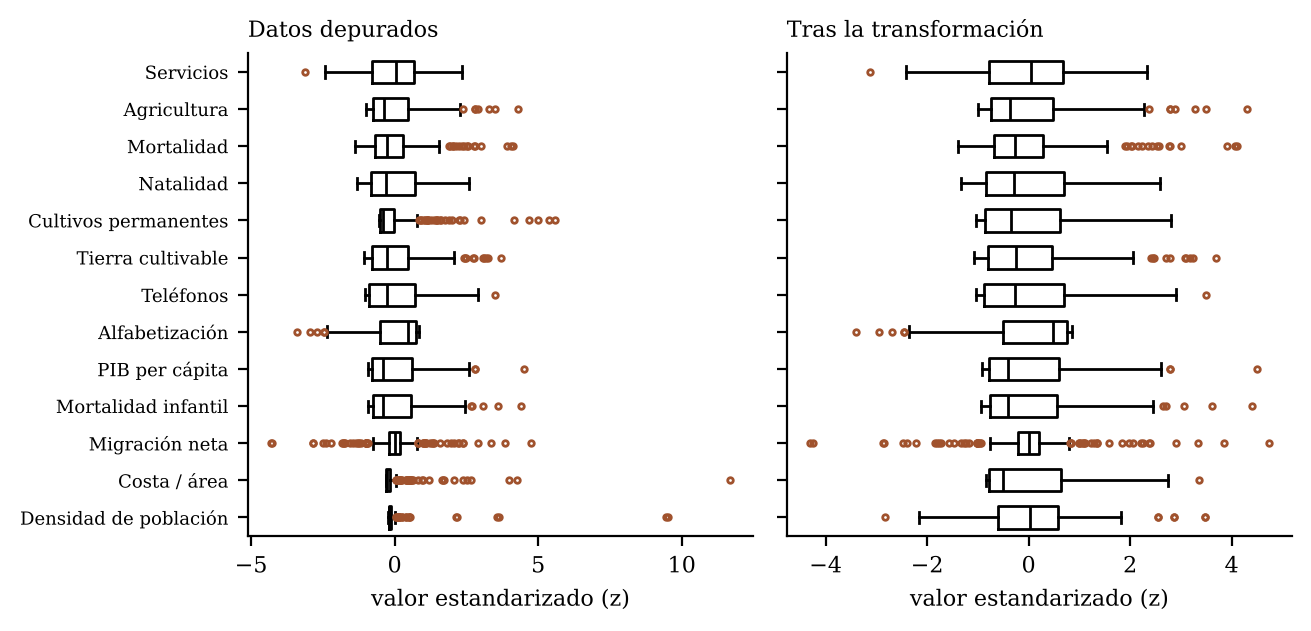

**Valores atípicos por el criterio del rango intercuartílico**

,antes,después,casos más alejados
Pop. Density (per sq. mi.),20,7,"Monaco, Macau, Singapore"
Coastline (coast/area ratio),37,1,"Micronesia, Fed. St., Palau, N. Mariana Islands"
Net migration,49,49,"Afghanistan, Micronesia, Fed. St., American Samoa"
Infant mortality (per 1000 births),5,5,"Angola, Afghanistan, Sierra Leone"
GDP ($ per capita),3,3,"Luxembourg, Norway, United States"
Literacy (%),5,5,"Niger, Burkina Faso, Sierra Leone"
Phones (per 1000),1,1,Monaco
Arable (%),10,10,"Bangladesh, Ukraine, Moldova"
Crops (%),28,0,"Kiribati, Sao Tome & Principe, Micronesia, Fed..."
Birthrate,0,0,


In [10]:
def zscores(df):
    return (df[VARS] - df[VARS].mean()) / df[VARS].std()


at_antes = {v: iqr_atipicos(datos[v]) for v in VARS}
at_despues = {v: iqr_atipicos(trans[v]) for v in VARS}
fig, (a, b) = plt.subplots(1, 2, figsize=(6.6, 3.2), sharey=True)
for ax, df, t in ((a, datos, "Datos depurados"), (b, trans, "Tras la transformación")):
    ax.boxplot(zscores(df).values, vert=False, widths=.6, medianprops=dict(color="black"),
               flierprops=dict(marker="o", ms=2, mfc="none", mec=C2))
    ax.set_title(t, loc="left", fontsize=8); ax.set_xlabel("valor estandarizado (z)")
a.set_yticks(range(1, len(VARS) + 1))
a.set_yticklabels([NOMBRES[v] for v in VARS], fontsize=6.5)
fig.tight_layout(); guardar(fig, "fig_atipicos.png")
RESULTADOS["atipicos"] = {v: [int(len(at_antes[v])), int(len(at_despues[v])), at_antes[v].index[:3].tolist()]
                          for v in VARS}
mostrar(pd.DataFrame({"antes": {v: len(at_antes[v]) for v in VARS}, "después": {v: len(at_despues[v]) for v in VARS},
                      "casos más alejados": {v: ", ".join(at_antes[v].index[:3]) for v in VARS}}),
        "Valores atípicos por el criterio del rango intercuartílico")

## 3.4 Correlaciones
### 3.4.1 Matriz de covarianza de la base transformada
Mapa de calor de la covarianza (escala logarítmica simétrica): el PIB per cápita domina por sus unidades.

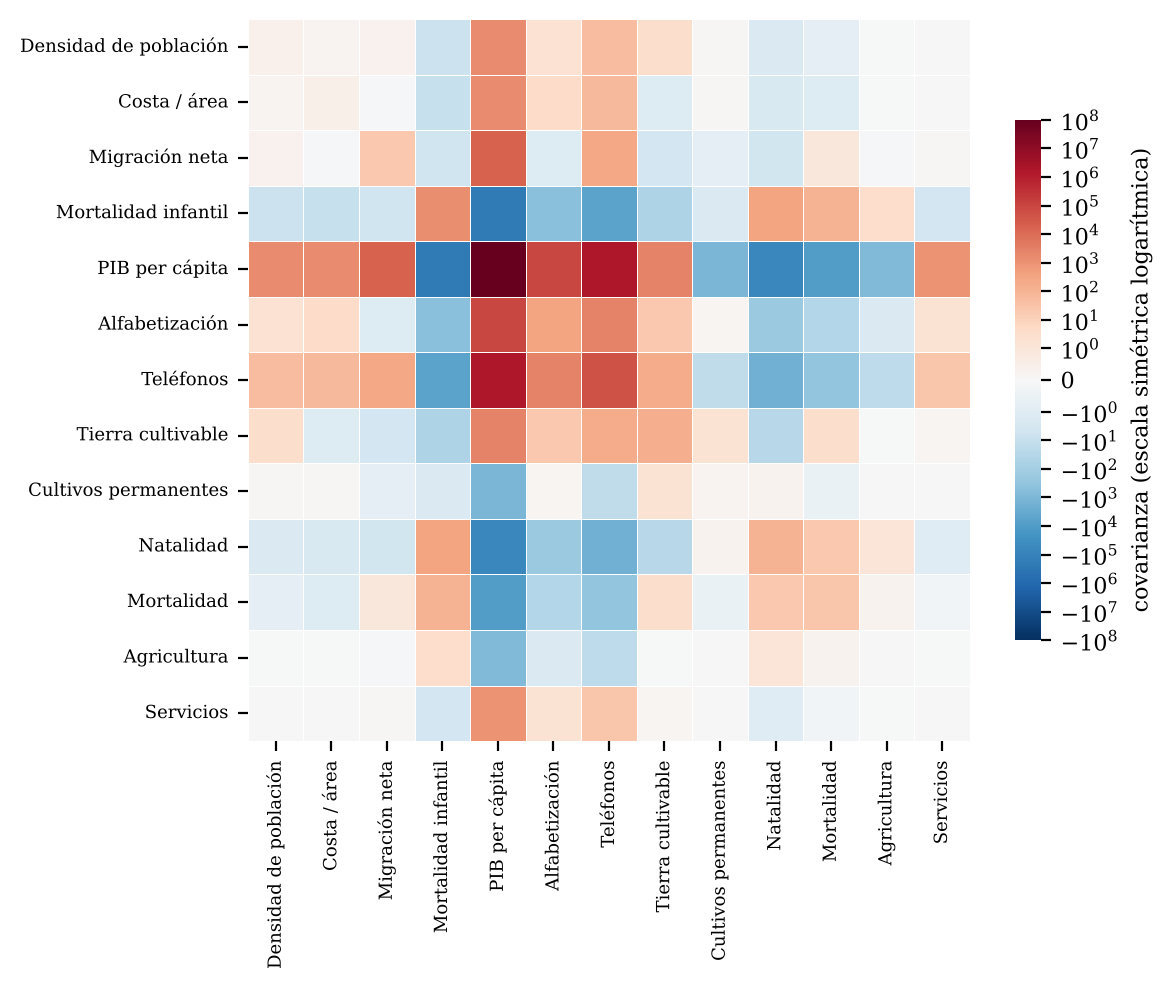

In [11]:
cov_t = trans[VARS].cov()
etq = [NOMBRES[v] for v in VARS]
fig, ax = plt.subplots(figsize=(5.9, 5.0))
sns.heatmap(cov_t, cmap="RdBu_r", norm=SymLogNorm(linthresh=1, vmin=-1e8, vmax=1e8, base=10),
            square=True, linewidths=.3, xticklabels=etq, yticklabels=etq, ax=ax,
            cbar_kws={"shrink": .7, "label": "covarianza (escala simétrica logarítmica)"})
ax.tick_params(labelsize=6.5)
fig.tight_layout(); guardar(fig, "fig_cov.png")
RESULTADOS["var_pib_trans"] = float(cov_t.loc["GDP ($ per capita)", "GDP ($ per capita)"])

### 3.4.2 Matriz de correlación de Pearson
Mapa de calor de la correlación y lista de los pares más y menos correlacionados.

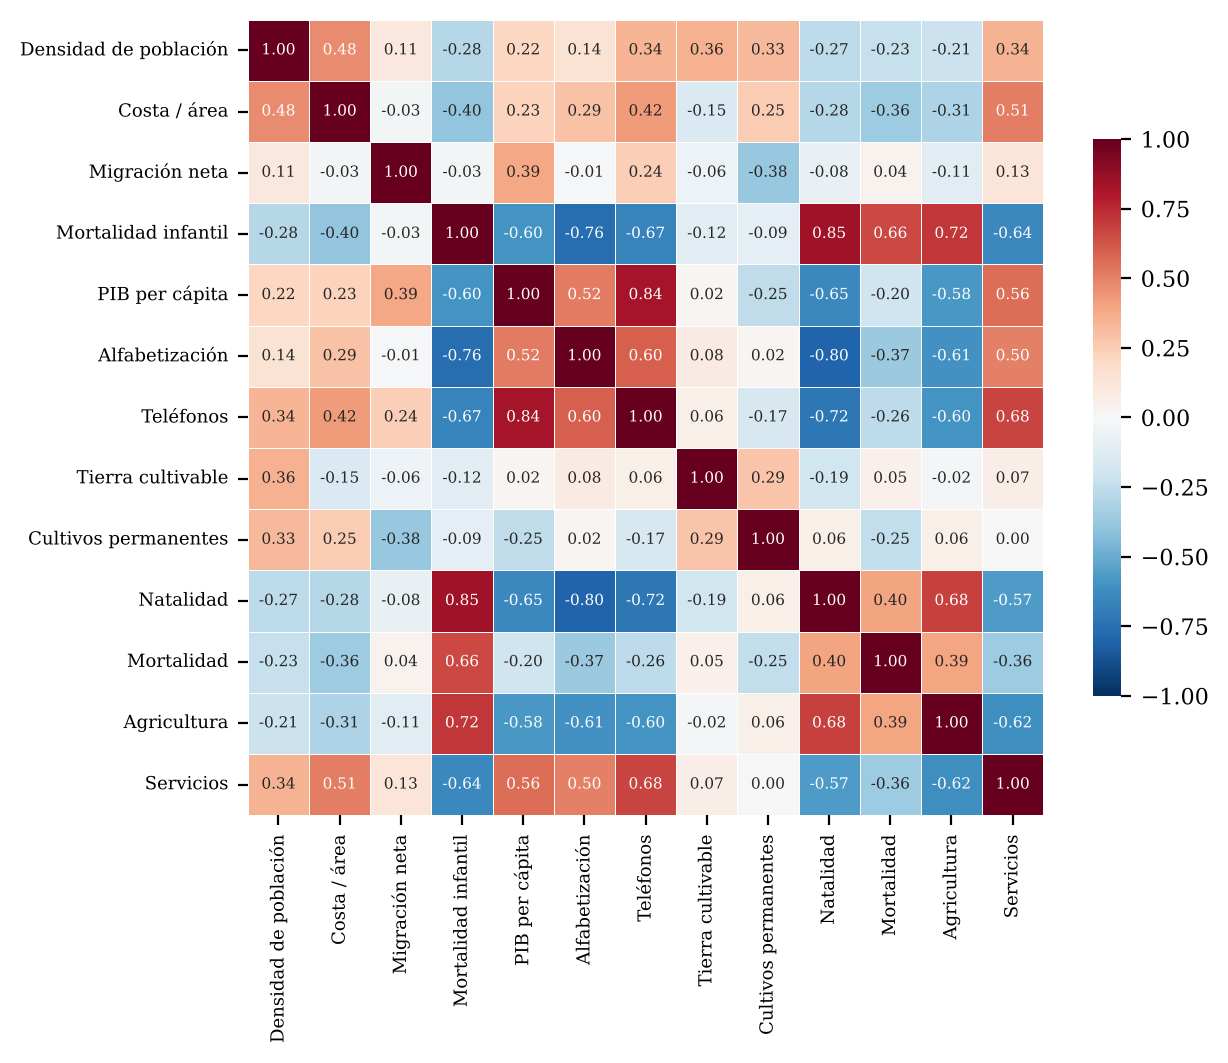

**Los ocho pares con mayor |r|**

,variable 1,variable 2,r
0,Infant mortality (per 1000 births),Birthrate,0.846
1,GDP ($ per capita),Phones (per 1000),0.836
2,Literacy (%),Birthrate,-0.800
3,Infant mortality (per 1000 births),Literacy (%),-0.760
4,Phones (per 1000),Birthrate,-0.723
5,Infant mortality (per 1000 births),Agriculture,0.718
6,Birthrate,Agriculture,0.681
7,Phones (per 1000),Service,0.679


**Los ocho pares con menor |r|**

,variable 1,variable 2,r
0,Crops (%),Service,0.005
1,Net migration,Literacy (%),-0.015
2,Arable (%),Agriculture,-0.018
3,GDP ($ per capita),Arable (%),0.019
4,Literacy (%),Crops (%),0.021
5,Coastline (coast/area ratio),Net migration,-0.029
6,Net migration,Infant mortality (per 1000 births),-0.029
7,Net migration,Deathrate,0.037


**Mayor correlación de cada variable**

,mayor |r|,con
Pop. Density (per sq. mi.),0.476229,Coastline (coast/area ratio)
Coastline (coast/area ratio),0.513027,Service
Net migration,0.389206,GDP ($ per capita)
Infant mortality (per 1000 births),0.846479,Birthrate
GDP ($ per capita),0.835535,Phones (per 1000)
Literacy (%),0.799901,Birthrate
Phones (per 1000),0.835535,GDP ($ per capita)
Arable (%),0.358883,Pop. Density (per sq. mi.)
Crops (%),0.379573,Net migration
Birthrate,0.846479,Infant mortality (per 1000 births)


In [12]:
corr = trans[VARS].corr(method="pearson")
etq = [NOMBRES[v] for v in VARS]
fig, ax = plt.subplots(figsize=(6.4, 5.3))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, square=True,
            linewidths=.3, annot_kws={"size": 5.5}, cbar_kws={"shrink": .7},
            xticklabels=etq, yticklabels=etq, ax=ax)
ax.tick_params(labelsize=6.5)
fig.tight_layout(); guardar(fig, "fig_corr.png")
corr.to_csv(RES / "matriz_correlacion.csv", encoding="utf-8")

p = len(VARS)
pares = sorted(((VARS[i], VARS[j], float(corr.iloc[i, j])) for i in range(p) for j in range(i + 1, p)),
               key=lambda t: abs(t[2]), reverse=True)
abs_r = np.array([abs(t[2]) for t in pares])
RESULTADOS["pares_top"] = pares[:8]
RESULTADOS["pares_bottom"] = pares[::-1][:8]
RESULTADOS["n_pares"] = len(pares)
RESULTADOS["n_pares_05"] = int((abs_r >= 0.5).sum())
RESULTADOS["n_pares_08"] = int((abs_r > 0.8).sum())
mayor = {}
for v in VARS:
    otros = corr[v].drop(v)
    w = otros.abs().idxmax()
    mayor[v] = [float(abs(otros[w])), w]
RESULTADOS["mayor_corr"] = mayor
_par = lambda t: pd.DataFrame(t, columns=["variable 1", "variable 2", "r"]).round(3)
mostrar(_par(pares[:8]), "Los ocho pares con mayor |r|")
mostrar(_par(pares[::-1][:8]), "Los ocho pares con menor |r|")
mostrar(pd.DataFrame(mayor, index=["mayor |r|", "con"]).T, "Mayor correlación de cada variable")

### 3.4.3 Variables más y menos relacionadas
Correlación mínima significativa (prueba *t*), grupo de cuatro variables con mayor |r| promedio y las dos
variables con menor |r| promedio frente a las demás.

In [13]:
abs_corr = corr.abs().to_numpy().copy()
np.fill_diagonal(abs_corr, 0.0)
# r_crit: correlación mínima significativa al 5 % con n países (prueba t de Pearson)
from scipy import stats
n = len(trans)
t_c = stats.t.ppf(0.975, n - 2)
r_crit = t_c / np.sqrt(n - 2 + t_c ** 2)
# Las 4 variables más correlacionadas: el grupo de 4 con mayor |r| promedio en sus 6 pares
mejor, top4 = -1.0, None
for comb in combinations(range(p), 4):
    puntaje = abs_corr[np.ix_(comb, comb)].sum() / 12      # cada par aparece dos veces
    if puntaje > mejor:
        mejor, top4 = puntaje, [VARS[k] for k in comb]
# Las 2 variables menos correlacionadas: menor |r| promedio con las otras 12 variables
intensidad = pd.Series(abs_corr.sum(axis=1) / (p - 1), index=VARS).sort_values()
bottom2 = intensidad.index[:2].tolist()
print("r crítico:", round(r_crit, 3), "| 4 más correlacionadas:", top4, round(mejor, 3))
print("2 menos correlacionadas:", bottom2, intensidad[bottom2].round(3).tolist())
mostrar(intensidad.sort_values(ascending=False).round(3).to_frame("|r| promedio con las demás"),
        "Intensidad media de asociación")

# Orden de presentación: primero el bloque de rezago (correlación negativa con el PIB per cápita)
# y después el de desarrollo (correlación positiva); cada bloque tiene su color en las figuras
signo_pib = corr.loc[top4, "GDP ($ per capita)"]
top4 = signo_pib.sort_values().index.tolist()


def color_bloque(v):
    if v in bottom2:
        return "gray"
    return C2 if corr.loc[v, "GDP ($ per capita)"] < 0 else C1

grupos_4 = []
for comb in combinations(range(p), 4):
    grupos_4.append((float(abs_corr[np.ix_(comb, comb)].sum() / 12), [VARS[k] for k in comb]))
grupos_4.sort(key=lambda g: g[0], reverse=True)
RESULTADOS.update({
    "r_crit": float(r_crit), "n_no_signif": int((abs_r < r_crit).sum()), "top4": top4,
    "top4_puntaje": float(mejor), "grupos_4": grupos_4[:4], "bottom2": bottom2,
    "intensidad": {v: float(x) for v, x in intensidad.items()},
})

r crítico: 0.131 | 4 más correlacionadas: ['Infant mortality (per 1000 births)', 'Literacy (%)', 'Birthrate', 'Agriculture'] 0.735
2 menos correlacionadas: ['Arable (%)', 'Net migration'] [0.121, 0.134]


**Intensidad media de asociación**

,|r| promedio con las demás
Infant mortality (per 1000 births),0.484
Phones (per 1000),0.466
Birthrate,0.462
GDP ($ per capita),0.421
Service,0.415
Agriculture,0.409
Literacy (%),0.393
Coastline (coast/area ratio),0.310
Deathrate,0.297
Pop. Density (per sq. mi.),0.276


### 3.4.4 Comparación gráfica de las variables más y menos correlacionadas
Matriz de dispersión de las cuatro variables más correlacionadas.

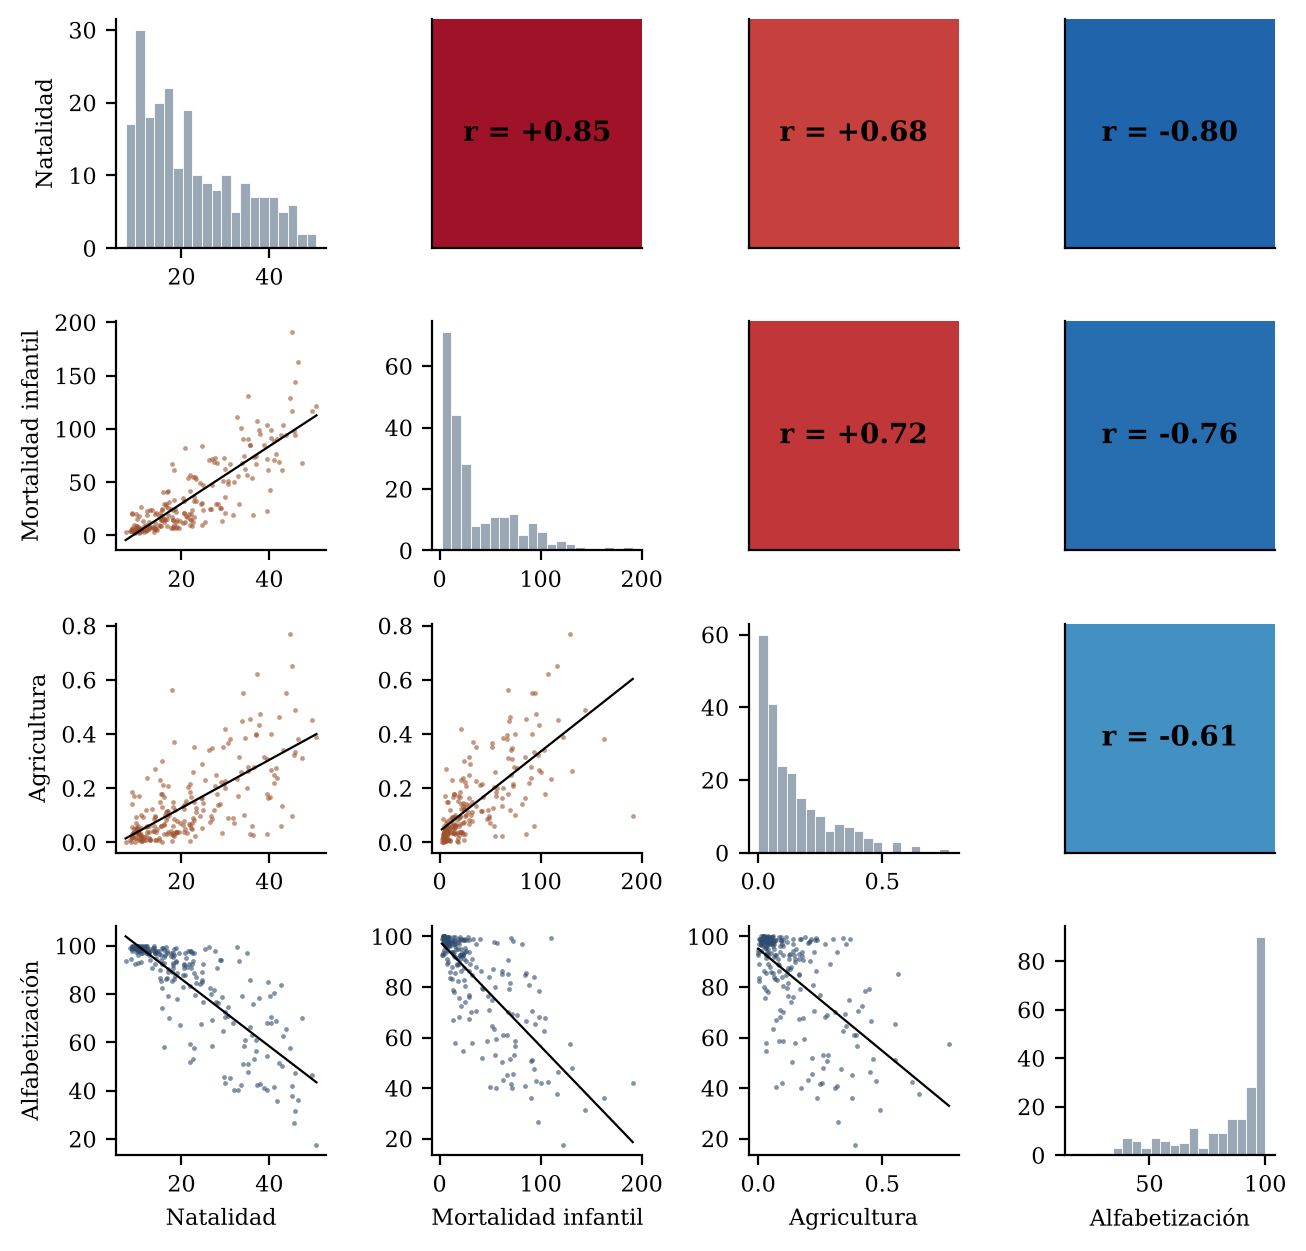

In [14]:
cmap_r = plt.get_cmap("RdBu_r")
fig, axes = plt.subplots(4, 4, figsize=(6.6, 6.3))
for i, vi in enumerate(top4):
    for j, vj in enumerate(top4):
        ax, r = axes[i, j], corr.loc[vi, vj]
        if i == j:                                   # diagonal: distribución de la variable
            ax.hist(trans[vi], bins=20, color="#9aa7b4", edgecolor="white", linewidth=.3)
        elif i > j:                                  # abajo: dispersión y recta de mínimos cuadrados
            ax.scatter(trans[vj], trans[vi], s=3, alpha=.6, linewidths=0, color=C2 if r > 0 else C1)
            m, c0 = np.polyfit(trans[vj], trans[vi], 1)
            xs = np.linspace(trans[vj].min(), trans[vj].max(), 50)
            ax.plot(xs, m * xs + c0, color="black", lw=.8)
        else:                                        # arriba: coeficiente r con el color del mapa de calor
            ax.set_facecolor(cmap_r((r + 1) / 2)); ax.set_xticks([]); ax.set_yticks([])
            ax.text(.5, .5, f"r = {r:+.2f}", ha="center", va="center", fontsize=10,
                    fontweight="bold", transform=ax.transAxes)
        ax.set_xlabel(NOMBRES[vj] if i == 3 else ""); ax.set_ylabel(NOMBRES[vi] if j == 0 else "")
fig.tight_layout(); guardar(fig, "fig_comparacion_correlaciones.png")

**Valores y vectores propios.** Se calculan los de la matriz de correlación de cada par de variables
(λ = 1 ± |r|) y los de cada grupo, y se dibujan los vectores propios de tres pares.

**Valores propios y primer vector propio de cada par**

,par,r,λ1,λ2,% en CP1,v1
0,Natalidad y Mortalidad infantil,0.846,1.846,0.154,92.324,"[0.71, 0.71]"
1,Natalidad y Agricultura,0.681,1.681,0.319,84.028,"[0.71, 0.71]"
2,Natalidad y Alfabetización,-0.800,1.800,0.200,89.995,"[0.71, -0.71]"
3,Mortalidad infantil y Agricultura,0.718,1.718,0.282,85.880,"[0.71, 0.71]"
4,Mortalidad infantil y Alfabetización,-0.760,1.760,0.240,87.999,"[0.71, -0.71]"
5,Agricultura y Alfabetización,-0.606,1.606,0.394,80.287,"[0.71, -0.71]"
6,Tierra cultivable y Migración neta,-0.057,1.057,0.943,52.874,"[0.71, -0.71]"


4 más correlacionadas, valores propios: [3.211 0.416 0.226 0.146] | CP1: 80.3 %
2 menos correlacionadas, valores propios: [1.057 0.943] | CP1: 52.9 %


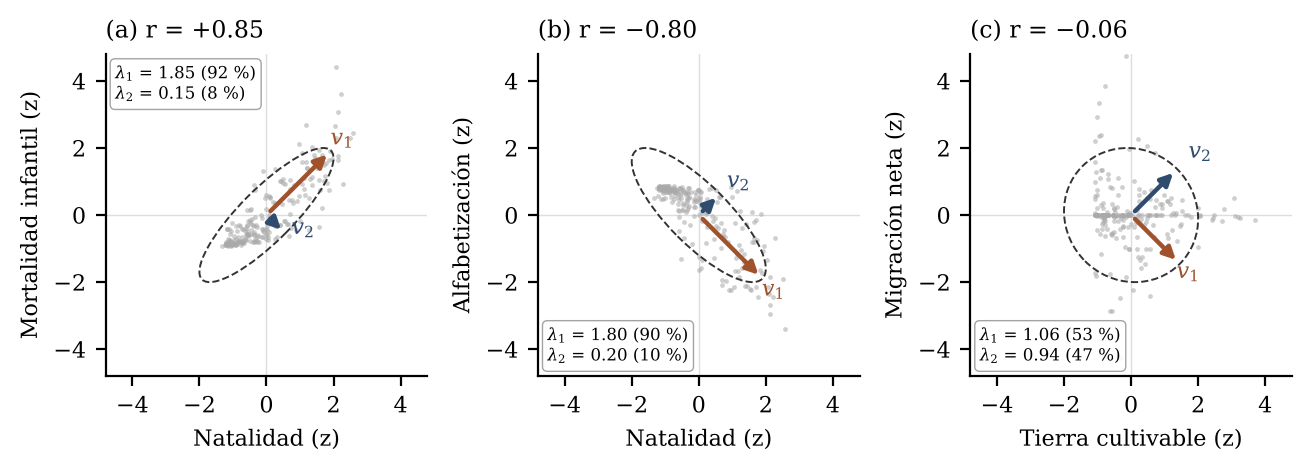

In [15]:
from matplotlib.patches import Ellipse
zt = (trans[VARS] - trans[VARS].mean()) / trans[VARS].std()

def eigen(vs):
    """Valores y vectores propios de la matriz de correlación de las variables vs, de mayor a menor."""
    vals, vecs = np.linalg.eigh(corr.loc[vs, vs].to_numpy())
    orden = np.argsort(vals)[::-1]
    vals, vecs = vals[orden], vecs[:, orden]
    return vals, vecs * np.where(vecs[0] < 0, -1, 1)          # signo: primera coordenada positiva

# Pares: R = [[1, r], [r, 1]] tiene valores propios 1 + |r| y 1 - |r| y vectores (1, 1)/√2 y (1, -1)/√2
eig_pares = []
for a_, b_ in list(combinations(top4, 2)) + [tuple(bottom2)]:
    vals, vecs = eigen([a_, b_])
    r_ = corr.loc[a_, b_]
    assert np.allclose(vals, [1 + abs(r_), 1 - abs(r_)])
    eig_pares.append((a_, b_, r_, vals, vecs[:, 0]))

# Grupos: las 4 variables más correlacionadas (matriz de 4 x 4) y las 2 menos correlacionadas (2 x 2)
val4, vec4 = eigen(top4)
val2, vec2 = eigen(bottom2)
mostrar(pd.DataFrame([{"par": f"{NOMBRES[a_]} y {NOMBRES[b_]}", "r": r_, "λ1": vals[0], "λ2": vals[1],
                       "% en CP1": 50 * vals[0], "v1": np.round(v1, 2)} for a_, b_, r_, vals, v1 in eig_pares]).round(3),
        "Valores propios y primer vector propio de cada par")
print("4 más correlacionadas, valores propios:", val4.round(3), "| CP1: %.1f %%" % (100 * val4[0] / 4))
print("2 menos correlacionadas, valores propios:", val2.round(3), "| CP1: %.1f %%" % (100 * val2[0] / 2))

# Figura: vectores propios de tres pares (el más correlacionado positivo y negativo del bloque y el de
# las dos menos correlacionadas). Flechas de longitud 2√λ y elipse de dos desviaciones estándar.
par_pos = max(combinations(top4, 2), key=lambda ab: corr.loc[ab[0], ab[1]])
par_neg = min(combinations(top4, 2), key=lambda ab: corr.loc[ab[0], ab[1]])
pares_fig = [par_pos, par_neg, tuple(bottom2)]
fig, axes = plt.subplots(1, 3, figsize=(6.6, 2.75))
lim = 4.8
for ax, (a_, b_), letra in zip(axes, pares_fig, "abc"):
    vals, vecs = eigen([a_, b_])
    r_ = corr.loc[a_, b_]
    ax.scatter(zt[a_], zt[b_], s=3, alpha=.55, linewidths=0, color="#a9a9a9")
    ang = np.degrees(np.arctan2(vecs[1, 0], vecs[0, 0]))
    ax.add_patch(Ellipse((0, 0), 4 * np.sqrt(vals[0]), 4 * np.sqrt(vals[1]), angle=ang,
                         fill=False, ls="--", lw=.7, ec="#333333"))
    for j, col in enumerate((C2, C1)):
        punta = vecs[:, j] * 2 * np.sqrt(vals[j])
        ax.annotate("", xy=punta, xytext=(0, 0),
                    arrowprops=dict(arrowstyle="-|>", color=col, lw=1.6, mutation_scale=9))
        ax.text(*(punta * 1.18 + (np.array([.45, .25]) if j == 1 else 0)), f"$v_{j + 1}$", color=col, fontsize=8,
                fontweight="bold", ha="center", va="center")
    esquina = (.03, .97, "top") if r_ > 0 else (.03, .03, "bottom")
    ax.text(esquina[0], esquina[1],
            f"$\\lambda_1$ = {vals[0]:.2f} ({50 * vals[0]:.0f} %)\n$\\lambda_2$ = {vals[1]:.2f} ({50 * vals[1]:.0f} %)",
            transform=ax.transAxes, fontsize=6, va=esquina[2], ha="left",
            bbox=dict(boxstyle="round,pad=.3", fc="white", ec="#999999", lw=.5, alpha=.9))
    ax.axhline(0, color="#dddddd", lw=.5, zorder=0); ax.axvline(0, color="#dddddd", lw=.5, zorder=0)
    ax.set_xlim(-lim, lim); ax.set_ylim(-lim, lim); ax.set_aspect("equal")
    ax.set_xticks([-4, -2, 0, 2, 4]); ax.set_yticks([-4, -2, 0, 2, 4])
    ax.set_xlabel(f"{NOMBRES[a_]} (z)"); ax.set_ylabel(f"{NOMBRES[b_]} (z)")
    ax.set_title(f"({letra}) r = {r_:+.2f}".replace("-", "−"), loc="left")
fig.tight_layout(); guardar(fig, "fig_vectores_pares.png")

RESULTADOS["eig_pares"] = [[a_, b_, float(r_), vals.tolist(), v1.tolist()] for a_, b_, r_, vals, v1 in eig_pares]
RESULTADOS["eig_top4"] = {"vals": val4.tolist(), "vecs": vec4.tolist()}
RESULTADOS["eig_bottom2"] = {"vals": val2.tolist(), "vecs": vec2.tolist()}
RESULTADOS["pares_fig_eig"] = [list(pr) for pr in pares_fig]

## 3.5 Componentes principales (PCA)
### 3.5.2 Cálculo
Se centran los datos, se calcula la matriz de covarianza (sin estandarizar y estandarizando) y se obtienen
sus valores y vectores propios con `numpy.linalg.eigh`, ordenados de mayor a menor. El signo de cada
vector se fija con una convención (CP1 con el PIB positivo). El resultado se compara con scikit-learn.

In [16]:
X = trans[VARS].to_numpy(float)
Xc = X - X.mean(axis=0)                       # datos centrados
S = np.cov(Xc, rowvar=False)                  # covarianza sin estandarizar
Z = Xc / X.std(axis=0, ddof=1)                # datos estandarizados
R = np.cov(Z, rowvar=False)                   # covarianza de los estandarizados (= matriz de correlación)


def pca_manual(M):
    valores, vectores = np.linalg.eigh(M)
    orden = np.argsort(valores)[::-1]
    valores, vectores = valores[orden], vectores[:, orden]
    for j in range(vectores.shape[1]):        # signo: CP1 con PIB positivo; en las demás, la mayor carga positiva
        ref = VARS.index("GDP ($ per capita)") if j == 0 else np.abs(vectores[:, j]).argmax()
        if vectores[ref, j] < 0:
            vectores[:, j] *= -1
    return valores, vectores


val_s, vec_s = pca_manual(S)                  # sin estandarizar
val_z, vec_z = pca_manual(R)                  # estandarizados

# Verificación con scikit-learn
skl = PCA().fit(Z)
RESULTADOS["verificacion_sklearn"] = bool(np.allclose(skl.explained_variance_, val_z))
RESULTADOS["cov_igual_corr"] = bool(np.allclose(R, np.corrcoef(X, rowvar=False)))
# Ejemplo numérico de los dos procedimientos (sección 3.4.2) con natalidad y mortalidad infantil
_a, _b = VARS.index("Birthrate"), VARS.index("Infant mortality (per 1000 births)")
RESULTADOS["ejemplo_cov_r"] = {
    "cov": float(S[_a, _b]), "s_a": float(X[:, _a].std(ddof=1)), "s_b": float(X[:, _b].std(ddof=1)),
    "cov_z": float(R[_a, _b])}

### 3.5.3 Número de componentes: criterio de Kaiser
Proporción de varianza de cada componente y número de valores propios mayores que 1.

Kaiser: 4 componentes


**Valores propios de la matriz de correlación**

,valor propio,% de varianza,% acumulado,mayor que 1
CP1,5.58,42.94,42.94,True
CP2,1.95,14.99,57.93,True
CP3,1.29,9.89,67.82,True
CP4,1.18,9.10,76.92,True
CP5,0.75,5.76,82.68,False
CP6,0.47,3.63,86.31,False
CP7,0.42,3.21,89.52,False
CP8,0.39,3.01,92.54,False
CP9,0.36,2.78,95.32,False
CP10,0.24,1.85,97.17,False


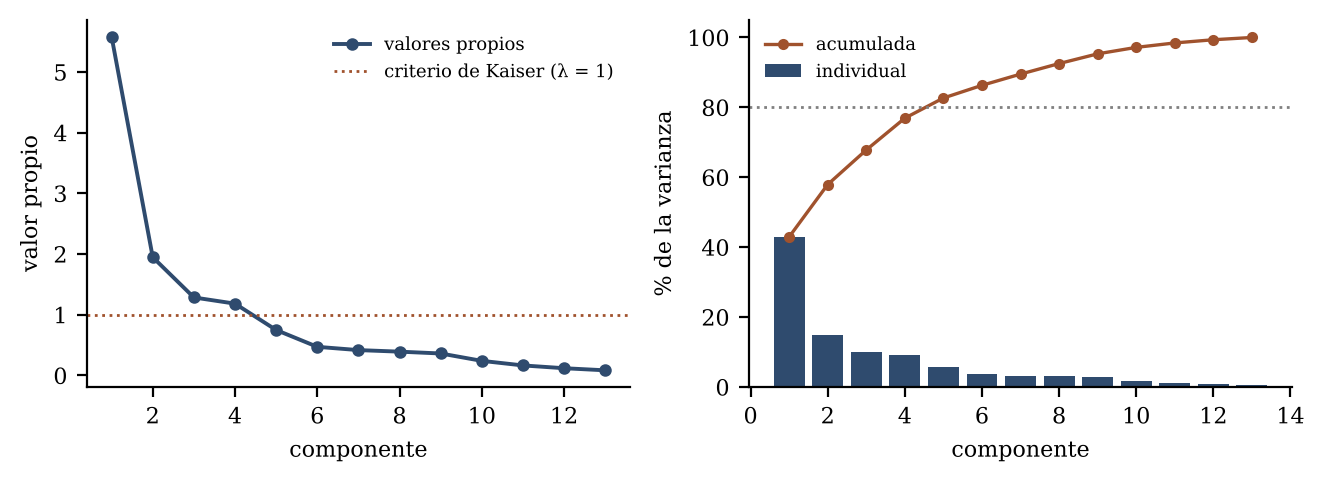

In [17]:
p = len(VARS)
prop_z = val_z / val_z.sum()                  # proporción de varianza de cada componente
acum_z = np.cumsum(prop_z)                    # proporción acumulada
k_kaiser = int((val_z > 1).sum())             # criterio de Kaiser: valores propios mayores que 1
k = k_kaiser
print("Kaiser:", k_kaiser, "componentes")
mostrar(pd.DataFrame({"valor propio": val_z, "% de varianza": 100 * prop_z, "% acumulado": 100 * acum_z,
                      "mayor que 1": val_z > 1}, index=[f"CP{i}" for i in range(1, p + 1)]).round(2),
        "Valores propios de la matriz de correlación")

RESULTADOS.update({
    "val_z": val_z.tolist(), "prop_z": prop_z.tolist(), "acum_z": acum_z.tolist(),
    "k_kaiser": k_kaiser, "k": k,
    "k_80": int(np.argmax(acum_z >= .80) + 1),     # componentes para llegar a 80 % (comparación de la sección 3.6.2)
})
pd.DataFrame({"valor_propio": val_z, "proporcion": prop_z, "acumulada": acum_z},
             index=[f"CP{i}" for i in range(1, p + 1)]).to_csv(RES / "valores_propios.csv", encoding="utf-8")

fig, (a, b) = plt.subplots(1, 2, figsize=(6.6, 2.45))
comp = np.arange(1, p + 1)
a.plot(comp, val_z, "o-", color=C1, ms=3.5, lw=1.4, label="valores propios")
a.axhline(1, color=C2, ls=":", lw=1, label="criterio de Kaiser (λ = 1)")
a.set_xlabel("componente"); a.set_ylabel("valor propio"); a.legend(frameon=False, fontsize=6.5)
b.bar(comp, 100 * prop_z, color=C1, label="individual")
b.plot(comp, 100 * acum_z, "o-", color=C2, ms=3, lw=1.2, label="acumulada")
b.axhline(80, color="gray", ls=":", lw=1)
b.set_xlabel("componente"); b.set_ylabel("% de la varianza"); b.legend(frameon=False, fontsize=6.5)
fig.tight_layout(); guardar(fig, "fig_scree.png")

### 3.5.4 Cargas
La carga de una variable en una componente es su coeficiente por la raíz del valor propio; con datos
estandarizados es la correlación entre ambas. También se calculan las puntuaciones de cada país.

**Cargas de las variables**

,CP1,CP2,CP3,CP4,CP5
Densidad de población,0.42,0.46,0.59,0.29,-0.03
Costa / área,0.53,0.36,-0.05,0.64,0.24
Migración neta,0.17,-0.58,0.46,0.29,-0.48
Mortalidad infantil,-0.91,-0.11,0.19,0.15,0.16
PIB per cápita,0.77,-0.42,0.19,0.00,0.05
Alfabetización,0.79,-0.00,-0.22,-0.30,0.09
Teléfonos,0.85,-0.23,0.17,0.06,0.21
Tierra cultivable,0.11,0.38,0.64,-0.58,-0.05
Cultivos permanentes,0.01,0.87,0.03,-0.02,-0.05
Natalidad,-0.88,0.06,0.05,0.31,-0.02


covarianza entre componentes (máx. fuera de la diagonal): 3.8e-15


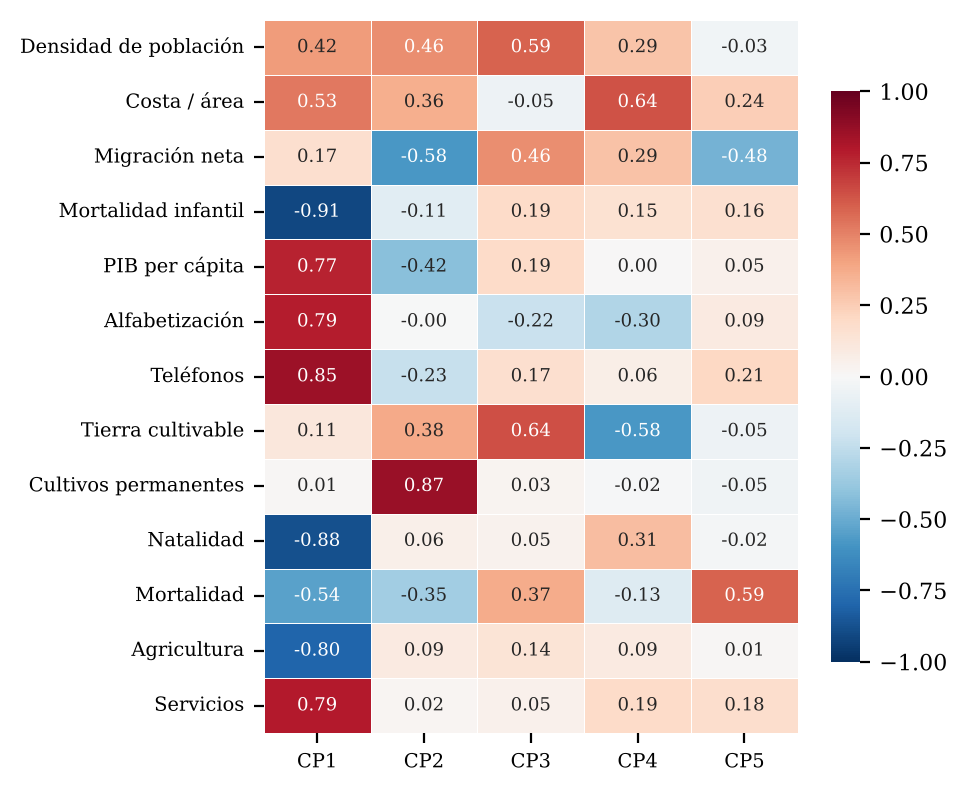

In [18]:
cargas = vec_z * np.sqrt(val_z)               # correlación entre variable y componente
CP = [f"CP{i}" for i in range(1, p + 1)]
tabla_cargas = pd.DataFrame(cargas, index=[NOMBRES[v] for v in VARS], columns=CP)
scores_z = Z @ vec_z
off = np.abs(np.cov(scores_z, rowvar=False) - np.diag(val_z)).max()
mostrar(tabla_cargas.iloc[:, :k + 1].round(2), "Cargas de las variables")
print("covarianza entre componentes (máx. fuera de la diagonal):", f"{off:.1e}")
tabla_cargas.to_csv(RES / "matriz_cargas.csv", encoding="utf-8")
RESULTADOS["cov_entre_cp"] = float(off)
RESULTADOS["cargas"] = {v: cargas[i, :6].tolist() for i, v in enumerate(VARS)}

fig, ax = plt.subplots(figsize=(4.8, 4.0))
sns.heatmap(tabla_cargas.iloc[:, :5], annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1,
            linewidths=.3, annot_kws={"size": 6.5}, cbar_kws={"shrink": .8}, ax=ax)
ax.tick_params(labelsize=7)
fig.tight_layout(); guardar(fig, "fig_cargas.png")

### 3.5.5 Países en el plano de las dos primeras componentes

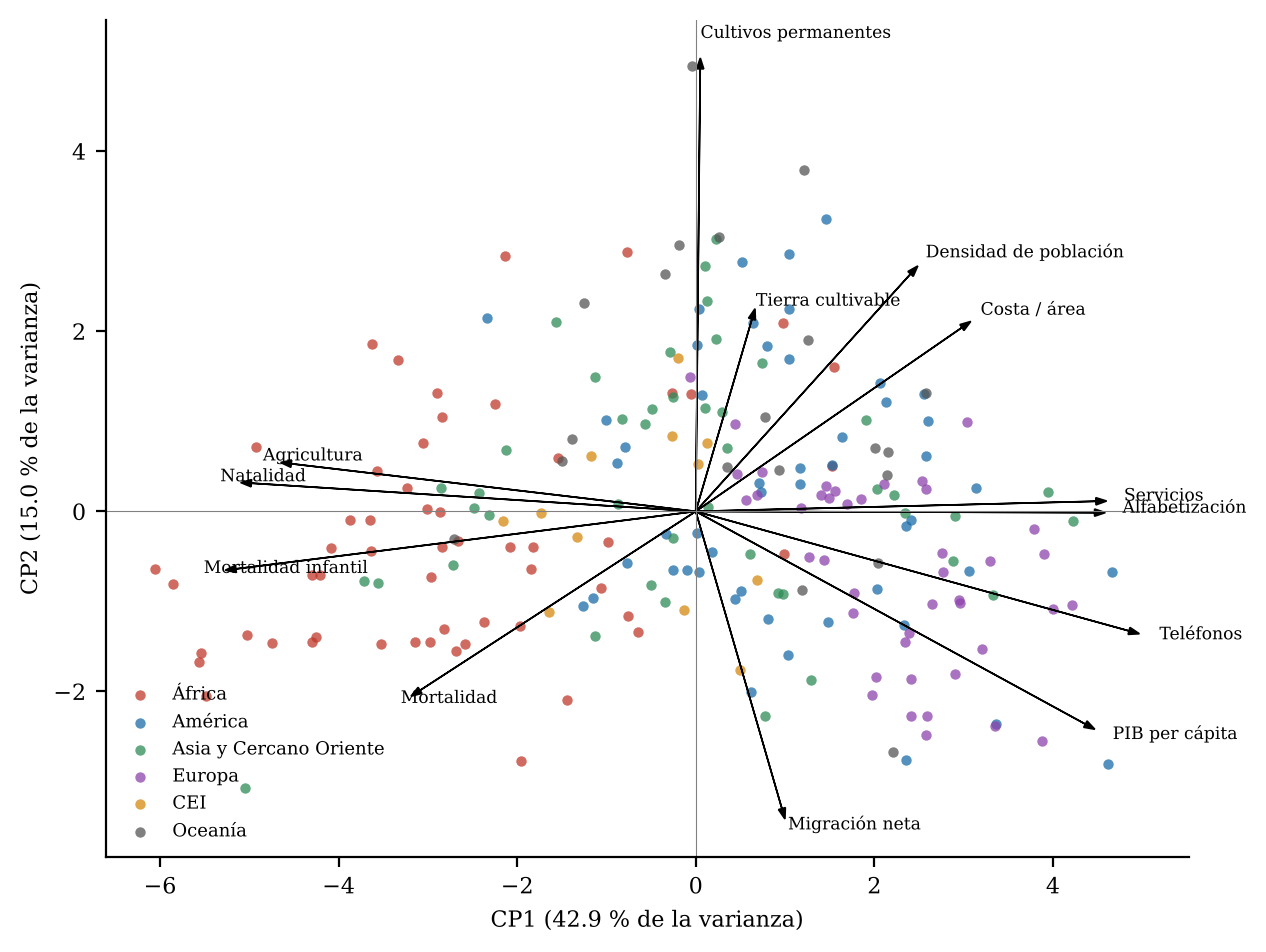

**Regiones sobre la CP1**

,puntuación media en CP1
Europa,2.22
América,1.04
Oceanía,0.58
Asia y Cercano Oriente,-0.06
CEI,-0.61
África,-2.71


In [19]:
grupos = trans["Region"].map(GRUPO)
fig, ax = plt.subplots(figsize=(6.4, 4.8))
for g, c in COLORES.items():
    m = (grupos == g).to_numpy()
    ax.scatter(scores_z[m, 0], scores_z[m, 1], s=14, color=c, alpha=.75, linewidths=0, label=g)
esc = 0.85 * np.abs(scores_z[:, :2]).max() / np.abs(cargas[:, :2]).max()
for i, v in enumerate(VARS):
    ax.arrow(0, 0, esc * cargas[i, 0], esc * cargas[i, 1], color="black", lw=.6, head_width=.08)
    ax.text(esc * cargas[i, 0] * 1.07, esc * cargas[i, 1] * 1.07, NOMBRES[v], fontsize=6.2)
ax.axhline(0, color="gray", lw=.4); ax.axvline(0, color="gray", lw=.4)
ax.set_xlabel(f"CP1 ({100 * prop_z[0]:.1f} % de la varianza)")
ax.set_ylabel(f"CP2 ({100 * prop_z[1]:.1f} % de la varianza)")
ax.legend(frameon=False, fontsize=6.5, loc="lower left")
fig.tight_layout(); guardar(fig, "fig_biplot.png")
cp1 = pd.Series(scores_z[:, 0], index=trans.index)
RESULTADOS["media_grupo_cp1"] = {g: float(cp1[(grupos == g).to_numpy()].mean())
                                 for g in cp1.groupby(grupos.to_numpy()).mean().sort_values(ascending=False).index}
RESULTADOS["cp1_altos"] = cp1.sort_values(ascending=False).index[:3].tolist()
RESULTADOS["cp1_bajos"] = cp1.sort_values().index[:3].tolist()
mostrar(pd.Series(RESULTADOS["media_grupo_cp1"]).round(2).to_frame("puntuación media en CP1"), "Regiones sobre la CP1")

### 3.5.6 Regresar a la matriz original
Con las primeras *k* componentes se reconstruye la matriz estandarizada (`T_k V_kᵀ`), se deshacen la
estandarización y el logaritmo y se mide el error para cada *k*. La tabla compara tres países.

con k = p se recupera la matriz original: True
error^2 = varianza no explicada: True
error relativo con k componentes: [0.755 0.649 0.567 0.48  0.416 0.37  0.324 0.273 0.216 0.168 0.125 0.081
 0.   ]


**Valores originales y reconstruidos**

original     k = 2     k = 4
Mexico  PIB per cápita        9000.00  11153.48   9288.05
        Mortalidad infantil     20.91     24.74     14.68
        Teléfonos              181.60    283.79    237.75
        Natalidad               20.69     19.20     16.54
Germany PIB per cápita       27600.00  22338.08  25099.72
        Mortalidad infantil      4.16     -1.85      1.35
        Teléfonos              667.90    517.22    553.99
        Natalidad                8.25      9.44      5.94
Niger   PIB per cápita         800.00  -3672.54  -2504.19
        Mortalidad infantil    121.69    114.95    125.31
        Teléfonos                1.90   -160.21   -120.48
        Natalidad               50.73     44.14     48.38

**Error de reconstrucción según k**

,error relativo,R² medio por variable
k,,
1,0.755,0.384
2,0.649,0.507
3,0.567,0.588
4,0.480,0.683
5,0.416,0.755
6,0.370,0.794
7,0.324,0.848
8,0.273,0.876
9,0.216,0.919


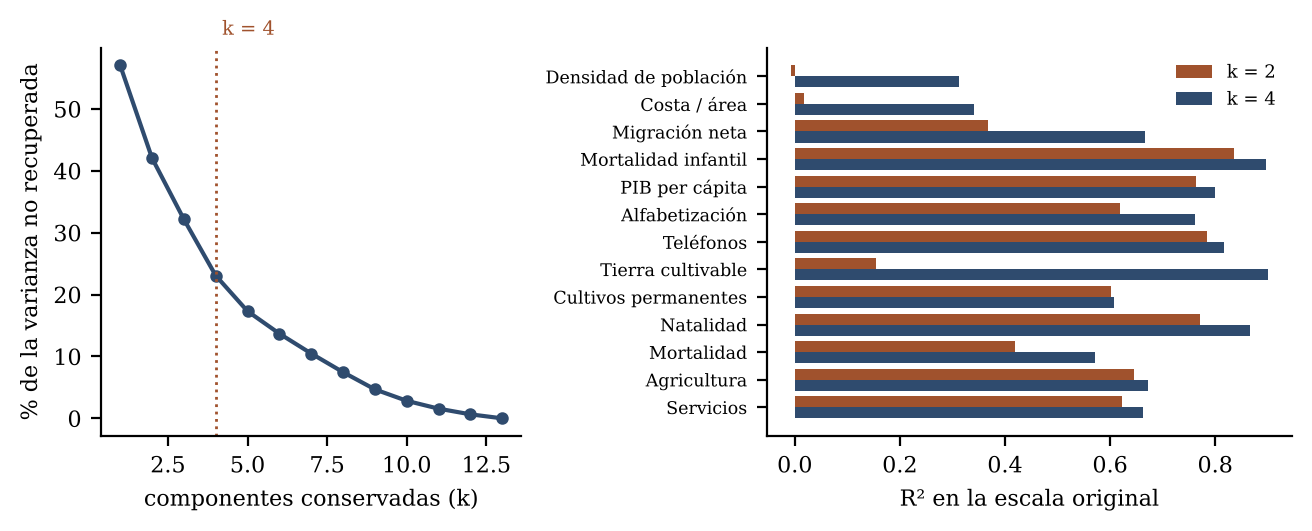

In [20]:
media, desv = X.mean(axis=0), X.std(axis=0, ddof=1)


def reconstruir(kk):
    Zk = scores_z[:, :kk] @ vec_z[:, :kk].T         # aproximación de Z con kk componentes
    Xk = Zk * desv + media                          # se deshace la estandarización
    for j, v in enumerate(VARS):
        if v in a_log:
            Xk[:, j] = 10 ** Xk[:, j] - 1           # se deshace log10(x + 1)
    return Zk, Xk


original = datos[VARS].to_numpy(float)
sst = ((original - original.mean(axis=0)) ** 2).sum(axis=0)
err_rel, r2_var = [], {}
for kk in range(1, p + 1):
    Zk, Xk = reconstruir(kk)
    err_rel.append(np.linalg.norm(Z - Zk) / np.linalg.norm(Z))
    r2_var[kk] = 1 - ((original - Xk) ** 2).sum(axis=0) / sst
err_rel = np.array(err_rel)
print("con k = p se recupera la matriz original:", np.allclose(reconstruir(p)[1], original))
print("error^2 = varianza no explicada:", np.allclose(err_rel ** 2, 1 - acum_z))
print("error relativo con k componentes:", np.round(err_rel, 3))
RESULTADOS["recon_ok"] = bool(np.allclose(reconstruir(p)[1], original))
RESULTADOS["recon_ident"] = bool(np.allclose(err_rel ** 2, 1 - acum_z))
RESULTADOS["err_rel"] = err_rel.tolist()
RESULTADOS["r2_k"] = {str(kk): {v: float(r2_var[kk][j]) for j, v in enumerate(VARS)} for kk in (2, k)}
_sel = ["Mexico", "Germany", "Niger"]
_cols = ["GDP ($ per capita)", "Infant mortality (per 1000 births)", "Phones (per 1000)", "Birthrate"]
_ix = [list(datos.index).index(c) for c in _sel]
_jx = [VARS.index(c) for c in _cols]
RESULTADOS["recon_paises"] = {
    "vars": _cols, "paises": _sel,
    "original": [[float(original[i, j]) for j in _jx] for i in _ix],
    "k2": [[float(reconstruir(2)[1][i, j]) for j in _jx] for i in _ix],
    "k4": [[float(reconstruir(k)[1][i, j]) for j in _jx] for i in _ix]}

_rp = RESULTADOS["recon_paises"]
mostrar(pd.DataFrame({"original": np.ravel(_rp["original"]), "k = 2": np.ravel(_rp["k2"]), f"k = {k}": np.ravel(_rp["k4"])},
                     index=pd.MultiIndex.from_product([_sel, [NOMBRES[c] for c in _cols]])).round(2),
        "Valores originales y reconstruidos")
mostrar(pd.DataFrame({"error relativo": err_rel, "R² medio por variable": [r2_var[kk].mean() for kk in range(1, p + 1)]},
                     index=pd.Index(range(1, p + 1), name="k")).round(3), "Error de reconstrucción según k")

fig, (a, b) = plt.subplots(1, 2, figsize=(6.6, 2.7), gridspec_kw={"width_ratios": [1, 1.25]})
a.plot(range(1, p + 1), 100 * (1 - acum_z), "o-", color=C1, ms=3.5)
a.axvline(k, color=C2, ls=":", lw=1)
a.text(k + .2, 62, f"k = {k}", color=C2, fontsize=7)
a.set_xlabel("componentes conservadas (k)"); a.set_ylabel("% de la varianza no recuperada")
y = np.arange(p)
b.barh(y - .2, r2_var[2], .4, color=C2, label="k = 2")
b.barh(y + .2, r2_var[k], .4, color=C1, label=f"k = {k}")
b.set_yticks(y); b.set_yticklabels([NOMBRES[v] for v in VARS], fontsize=6.3); b.invert_yaxis()
b.set_xlabel("R² en la escala original"); b.legend(frameon=False, fontsize=6.5)
fig.tight_layout(); guardar(fig, "fig_recon.png")

## 3.6 Estandarización: con y sin
Rango y varianza de cada variable antes de estandarizar, y comparación del PCA sin estandarizar (matriz de
covarianza) y estandarizando (matriz de correlación).

**Rango y varianza de cada variable (base transformada)**

,minimo,maximo,rango,varianza
Pop. Density (per sq. mi.),0.000,4.211,4.211,4.480000e-01
Coastline (coast/area ratio),0.000,2.940,2.940,4.930000e-01
Net migration,-20.990,23.060,44.050,2.370600e+01
Infant mortality (per 1000 births),2.290,191.190,188.900,1.250524e+03
GDP ($ per capita),500.000,55100.000,54600.000,1.015012e+08
Literacy (%),17.600,100.000,82.400,3.739130e+02
Phones (per 1000),0.200,1035.600,1035.400,5.209435e+04
Arable (%),0.000,62.110,62.110,1.696500e+02
Crops (%),0.000,1.713,1.713,1.980000e-01
Birthrate,7.290,50.730,43.440,1.234810e+02


varianza de CP1 sin estandarizar: 99.98 %
varianza de CP1 estandarizando:   42.94 %
carga de CP1 (sin estandarizar) sobre el PIB: 0.9998
correlación entre las puntuaciones de CP1 de ambos casos: 0.769


**PCA con y sin estandarización**

,sin estandarizar,estandarizados
matriz usada,covarianza,correlación
varianza explicada por la CP1,99.98 %,42.9 %
componentes para llegar a 80 %,1,5
variables con peso importante en la CP1,1,9


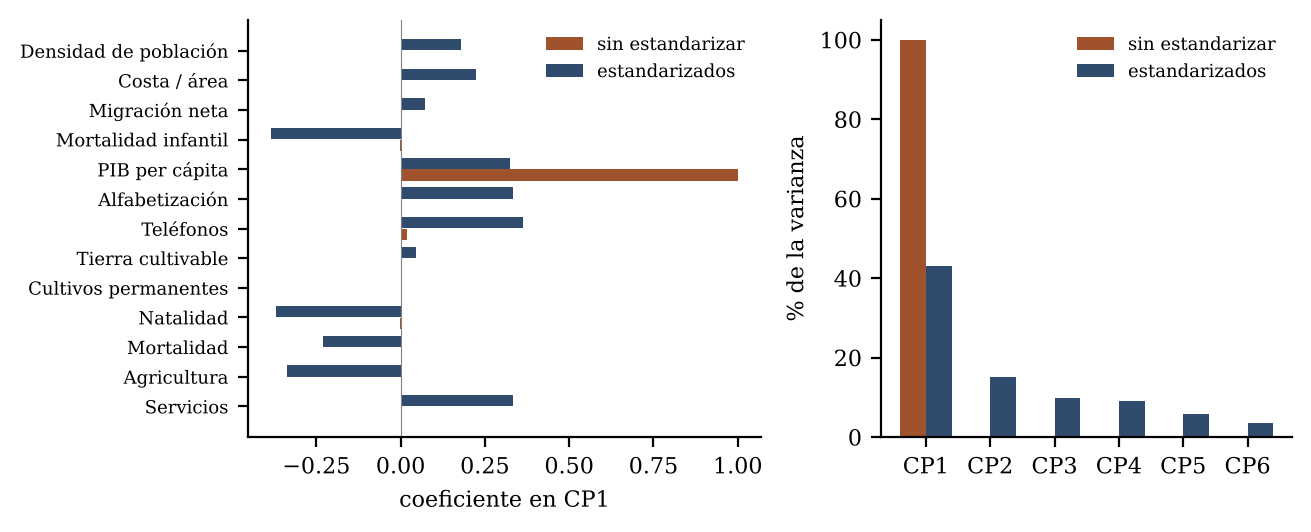

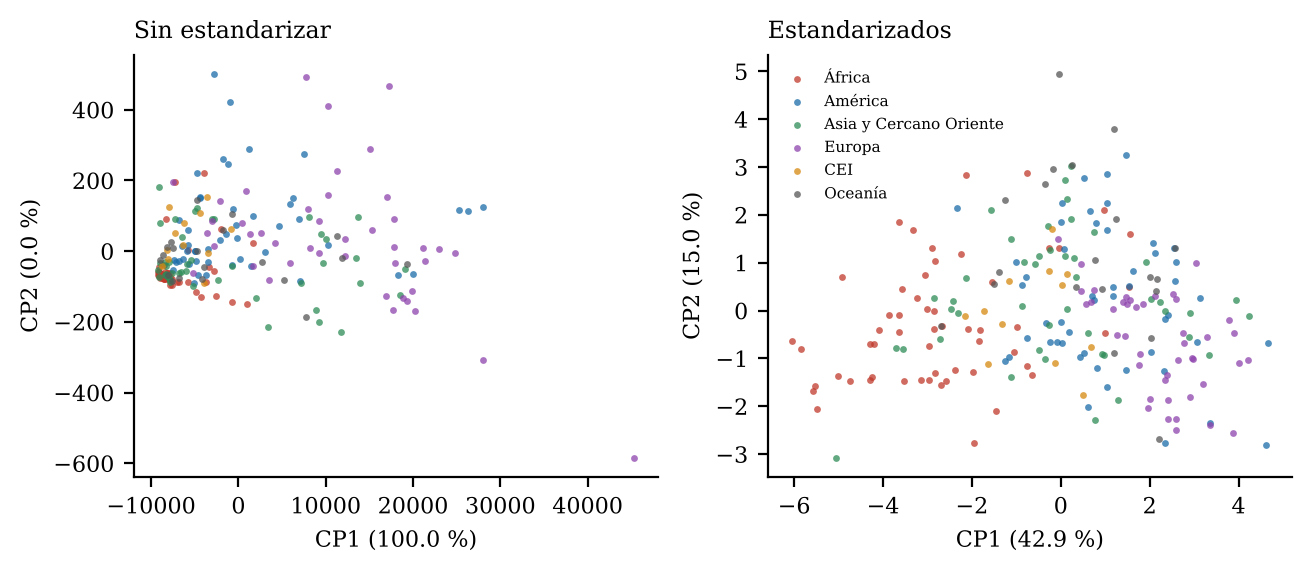

In [21]:
rango = pd.DataFrame({"minimo": trans[VARS].min(), "maximo": trans[VARS].max(),
                      "rango": trans[VARS].max() - trans[VARS].min(), "varianza": trans[VARS].var()})
rango.to_csv(RES / "rango_varianza_transformada.csv", encoding="utf-8")
RESULTADOS["peso_pib"] = float(trans["GDP ($ per capita)"].var() / trans[VARS].var().sum())
mostrar(rango.round(3), "Rango y varianza de cada variable (base transformada)")

prop_s = val_s / val_s.sum()
scores_s = Xc @ vec_s
cargas_s = vec_s * np.sqrt(val_s)
r_cp1 = np.corrcoef(scores_s[:, 0], scores_z[:, 0])[0, 1]
print("varianza de CP1 sin estandarizar: %.2f %%" % (100 * prop_s[0]))
print("varianza de CP1 estandarizando:   %.2f %%" % (100 * prop_z[0]))
print("carga de CP1 (sin estandarizar) sobre el PIB:", round(vec_s[VARS.index("GDP ($ per capita)"),
      0], 4))
print("correlación entre las puntuaciones de CP1 de ambos casos:", round(r_cp1, 3))
RESULTADOS.update({
    "prop_s": prop_s.tolist(), "k_80_s": int(np.argmax(np.cumsum(prop_s) >= .80) + 1),
    "vec_s_pib": float(vec_s[VARS.index("GDP ($ per capita)"), 0]), "r_cp1": float(r_cp1),
    "n_cargas_05": int((np.abs(cargas[:, 0]) >= 0.5).sum()),
})
mostrar(pd.DataFrame({
    "sin estandarizar": ["covarianza", f"{100 * prop_s[0]:.2f} %", RESULTADOS["k_80_s"], 1],
    "estandarizados": ["correlación", f"{100 * prop_z[0]:.1f} %", RESULTADOS["k_80"], RESULTADOS["n_cargas_05"]]},
    index=["matriz usada", "varianza explicada por la CP1", "componentes para llegar a 80 %",
           "variables con peso importante en la CP1"]), "PCA con y sin estandarización")

fig, (a, b) = plt.subplots(1, 2, figsize=(6.6, 2.7), gridspec_kw={"width_ratios": [1.25, 1]})
y = np.arange(p)
a.barh(y + .2, vec_s[:, 0], height=.38, color=C2, label="sin estandarizar")
a.barh(y - .2, vec_z[:, 0], height=.38, color=C1, label="estandarizados")
a.set_yticks(y); a.set_yticklabels([NOMBRES[v] for v in VARS], fontsize=6.5); a.invert_yaxis()
a.axvline(0, color="gray", lw=.4); a.set_xlabel("coeficiente en CP1"); a.legend(frameon=False, fontsize=6.5)
x6 = np.arange(6)
b.bar(x6 - .2, 100 * prop_s[:6], width=.4, color=C2, label="sin estandarizar")
b.bar(x6 + .2, 100 * prop_z[:6], width=.4, color=C1, label="estandarizados")
b.set_xticks(x6); b.set_xticklabels([f"CP{i}" for i in range(1, 7)])
b.set_ylabel("% de la varianza"); b.legend(frameon=False, fontsize=6.5)
fig.tight_layout(); guardar(fig, "fig_cp1_comparacion.png")

fig, axes = plt.subplots(1, 2, figsize=(6.6, 2.9))
for ax, sc, pr, t in ((axes[0], scores_s, prop_s, "Sin estandarizar"), (axes[1], scores_z, prop_z, "Estandarizados")):
    for g, c in COLORES.items():
        m = (grupos == g).to_numpy()
        ax.scatter(sc[m, 0], sc[m, 1], s=6, color=c, alpha=.75, linewidths=0, label=g)
    ax.set_xlabel(f"CP1 ({100 * pr[0]:.1f} %)"); ax.set_ylabel(f"CP2 ({100 * pr[1]:.1f} %)")
    ax.set_title(t, loc="left")
axes[1].legend(frameon=False, fontsize=5.5, loc="upper left")
fig.tight_layout(); guardar(fig, "fig_planos.png")

## 3.7 Predicción con splines cúbicos
La base es de un solo momento, así que la predicción se hace **a través de los países**: un spline cúbico
natural aprende cómo cambia la **mortalidad infantil** a lo largo del **PIB per cápita** y con esa curva se
predice la mortalidad infantil de países que no se usaron para construirla.

1. Se apartan 8 países de prueba con distintos niveles de PIB (Yemen, Togo, Saint Helena, Jamaica,
   Namibia, México, Letonia y Jersey). Con los demás países que tienen ambos datos observados se
   construye la curva.
2. Los países de entrenamiento se ordenan por PIB y se dividen en 8 grupos; cada grupo aporta un nodo
   (mediana del PIB, mediana de la mortalidad infantil), como en la sección 2.3.
3. Por los nodos pasa un spline cúbico natural, que se obtiene resolviendo el sistema tridiagonal de sus
   coeficientes (`spline_natural`) y se comprueba contra `scipy.interpolate.CubicSpline`.
4. Se predice la mortalidad infantil de los países de prueba y se compara con su valor real, con el spline
   y con la interpolación lineal entre los mismos nodos.
5. La derivada del spline indica cuánto cambia la mortalidad infantil por cada 1,000 dólares de PIB en
   cada punto de la curva.

países de entrenamiento: 215 | de prueba: 8
spline_natural coincide con scipy.interpolate.CubicSpline: True


**Nodos del spline**

,PIB per cápita,mortalidad infantil
0,800.0,94.69
1,1600.0,67.83
2,2500.0,51.43
3,4800.0,24.18
4,6900.0,20.76
5,11400.0,11.95
6,19200.0,6.94
7,29000.0,4.69


**Coeficientes del spline: S_j(x) = a + b (x - x_j) + c (x - x_j)^2 + d (x - x_j)^3**

,intervalo,a,b,c,d
0,"800-1,600",94.69,-0.037207,4.362220e-20,5.674311e-09
1,"1,600-2,500",67.83,-0.026312,1.361835e-05,-5.144262e-09
2,"2,500-4,800",51.43,-0.014299,-2.711609e-07,5.813344e-10
3,"4,800-6,900",24.18,-0.006321,3.740046e-06,-7.169364e-10
4,"6,900-11,400",20.76,-0.000098,-7.766534e-07,8.074156e-11
5,"11,400-19,200",11.95,-0.002183,3.133577e-07,-1.485557e-11
6,"19,200-29,000",6.94,-0.000006,-3.426257e-08,1.165393e-12


**Predicción de los países de prueba**

,PIB,real,spline,lineal,error_spline,error_lineal
Country,,,,,,
Yemen,800.0,61.50,94.69,94.69,33.19,33.19
Togo,1500.0,66.61,70.59,71.19,3.98,4.58
Saint Helena,2500.0,19.00,51.43,51.43,32.43,32.43
Jamaica,3900.0,12.36,32.47,34.84,20.11,22.48
Namibia,7200.0,48.98,20.66,20.17,-28.32,-28.81
Mexico,9000.0,20.91,17.88,16.65,-3.03,-4.26
Latvia,10200.0,9.55,14.88,14.30,5.33,4.75
Jersey,24800.0,5.24,6.04,5.65,0.80,0.41


RMSE spline: 20.66 | lineal: 21.07 | solo la media: 23.56


**Derivada del spline**

,"cambio por cada 1,000 dólares"
1000,-36.53
5000,-4.91
10000,-2.59
20000,-0.06


México: PIB 9000, real 20.91, spline 17.88; con el doble de PIB: 6.92


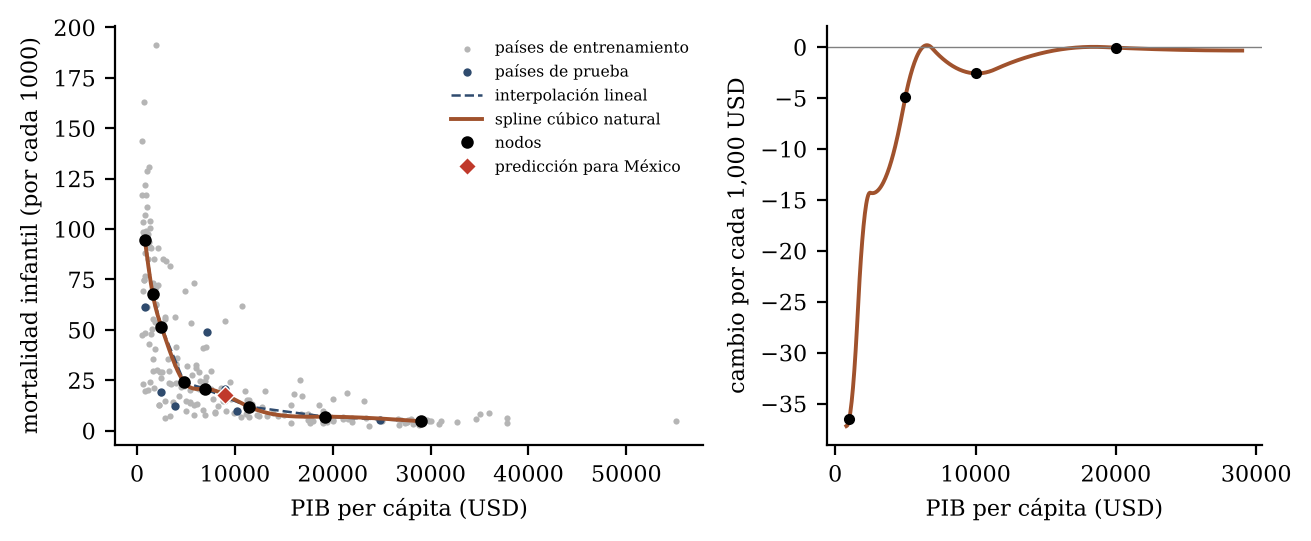

In [22]:
def spline_natural(xn, yn):
    """Coeficientes a, b, c, d de S_j(x) = a_j + b_j (x - x_j) + c_j (x - x_j)^2 + d_j (x - x_j)^3."""
    xn, yn = np.asarray(xn, float), np.asarray(yn, float)
    n = len(xn) - 1
    h = np.diff(xn)
    A, lado = np.zeros((n + 1, n + 1)), np.zeros(n + 1)
    A[0, 0] = A[n, n] = 1.0                                     # spline natural: S''(x_0) = S''(x_n) = 0
    for j in range(1, n):                                       # continuidad de S' y S'' en los nodos interiores
        A[j, j - 1], A[j, j], A[j, j + 1] = h[j - 1], 2 * (h[j - 1] + h[j]), h[j]
        lado[j] = 3 * ((yn[j + 1] - yn[j]) / h[j] - (yn[j] - yn[j - 1]) / h[j - 1])
    c = np.linalg.solve(A, lado)
    b = np.diff(yn) / h - h * (2 * c[:-1] + c[1:]) / 3
    d = np.diff(c) / (3 * h)
    return yn[:-1], b, c[:-1], d


def evaluar(xn, yn, x, metodo, extrapolar=False):
    """Valor de la interpolación (lineal o spline cúbico) en x. Fuera de los nodos se usa el nodo extremo."""
    xn, yn = np.asarray(xn, float), np.asarray(yn, float)
    x = np.atleast_1d(np.asarray(x, float))
    if not extrapolar:
        x = np.clip(x, xn[0], xn[-1])
    if metodo == "lineal":
        return np.interp(x, xn, yn)
    a, b, c, d = spline_natural(xn, yn)
    j = np.clip(np.searchsorted(xn, x, side="right") - 1, 0, len(xn) - 2)
    t = x - xn[j]
    return a[j] + b[j] * t + c[j] * t ** 2 + d[j] * t ** 3


def derivada(xn, yn, x):
    """Derivada del spline cúbico natural: S_j'(x) = b_j + 2 c_j (x - x_j) + 3 d_j (x - x_j)^2."""
    xn = np.asarray(xn, float)
    x = np.clip(np.atleast_1d(np.asarray(x, float)), xn[0], xn[-1])
    a, b, c, d = spline_natural(xn, yn)
    j = np.clip(np.searchsorted(xn, x, side="right") - 1, 0, len(xn) - 2)
    t = x - xn[j]
    return b[j] + 2 * c[j] * t + 3 * d[j] * t ** 2


from scipy.interpolate import CubicSpline
X_SP, Y_SP = "GDP ($ per capita)", "Infant mortality (per 1000 births)"
base_sp = observados[[X_SP, Y_SP]].dropna()                     # solo valores observados (sin imputar)
PAISES_PRUEBA = ["Yemen", "Togo", "Saint Helena", "Jamaica", "Namibia", "Mexico", "Latvia", "Jersey"]
assert all(p in base_sp.index for p in PAISES_PRUEBA)
es_prueba = base_sp.index.isin(PAISES_PRUEBA)
entren, prueba = base_sp[~es_prueba], base_sp[es_prueba]
xn_p, yn_p = nodos(entren[X_SP], entren[Y_SP])
a_p, b_p, c_p, d_p = spline_natural(xn_p, yn_p)
_xs = np.linspace(xn_p[0], xn_p[-1], 2000)
spline_ok = bool(np.allclose(evaluar(xn_p, yn_p, _xs, "cubico"), CubicSpline(xn_p, yn_p, bc_type="natural")(_xs)))
print("países de entrenamiento:", len(entren), "| de prueba:", len(prueba))
print("spline_natural coincide con scipy.interpolate.CubicSpline:", spline_ok)
RESULTADOS["spline_ok"] = spline_ok
mostrar(pd.DataFrame({"PIB per cápita": xn_p, "mortalidad infantil": yn_p}).round(2), "Nodos del spline")
mostrar(pd.DataFrame({"intervalo": [f"{xn_p[j]:,.0f}-{xn_p[j + 1]:,.0f}" for j in range(len(xn_p) - 1)],
                      "a": a_p, "b": b_p, "c": c_p, "d": d_p}),
        "Coeficientes del spline: S_j(x) = a + b (x - x_j) + c (x - x_j)^2 + d (x - x_j)^3")

pred_p = pd.DataFrame({"PIB": prueba[X_SP], "real": prueba[Y_SP],
                       "spline": evaluar(xn_p, yn_p, prueba[X_SP], "cubico"),
                       "lineal": evaluar(xn_p, yn_p, prueba[X_SP], "lineal")}).sort_values("PIB")
pred_p["error_spline"] = pred_p["spline"] - pred_p["real"]
pred_p["error_lineal"] = pred_p["lineal"] - pred_p["real"]
mostrar(pred_p.round(2), "Predicción de los países de prueba")
rmse_p = {m: float(np.sqrt((pred_p[f"error_{m}"] ** 2).mean())) for m in ("spline", "lineal")}
rmse_p["media"] = float(np.sqrt(((entren[Y_SP].mean() - prueba[Y_SP]) ** 2).mean()))   # referencia sin PIB
print("RMSE spline: %.2f | lineal: %.2f | solo la media: %.2f" % (rmse_p["spline"], rmse_p["lineal"], rmse_p["media"]))

PIB_DER = [1000, 5000, 10000, 20000]
der_p = {int(v): float(1000 * derivada(xn_p, yn_p, v)[0]) for v in PIB_DER}   # cambio por cada 1,000 dólares
mostrar(pd.Series(der_p).round(2).to_frame("cambio por cada 1,000 dólares"), "Derivada del spline")
pos = _xs[derivada(xn_p, yn_p, _xs) > 0]
mex_pib, mex_real = float(raw.loc["Mexico", X_SP]), float(raw.loc["Mexico", Y_SP])
mex = {"pib": mex_pib, "real": mex_real, "pred": float(evaluar(xn_p, yn_p, mex_pib, "cubico")[0]),
       "pred_doble": float(evaluar(xn_p, yn_p, 2 * mex_pib, "cubico")[0]), "en_prueba": bool("Mexico" in prueba.index),
       "j": int(np.searchsorted(xn_p, mex_pib, side="right") - 1)}
print("México: PIB %.0f, real %.2f, spline %.2f; con el doble de PIB: %.2f" % (mex_pib, mex_real, mex["pred"], mex["pred_doble"]))

fig, (a, b) = plt.subplots(1, 2, figsize=(6.6, 2.75), gridspec_kw={"width_ratios": [1.35, 1]})
xs = np.linspace(xn_p[0], xn_p[-1], 600)
a.scatter(entren[X_SP], entren[Y_SP], s=5, color="#b5b5b5", linewidths=0, label="países de entrenamiento")
a.scatter(prueba[X_SP], prueba[Y_SP], s=9, color=C1, linewidths=0, label="países de prueba")
a.plot(xs, evaluar(xn_p, yn_p, xs, "lineal"), color=C1, lw=.9, ls="--", label="interpolación lineal")
a.plot(xs, evaluar(xn_p, yn_p, xs, "cubico"), color=C2, lw=1.4, label="spline cúbico natural")
a.plot(xn_p, yn_p, "o", color="black", ms=3.5, label="nodos")
a.plot([mex_pib], [mex["pred"]], "D", color="#c0392b", ms=4.5, mec="white", mew=.5, label="predicción para México")
a.set_xlabel("PIB per cápita (USD)"); a.set_ylabel("mortalidad infantil (por cada 1000)")
a.legend(frameon=False, fontsize=5.6)
b.plot(xs, 1000 * derivada(xn_p, yn_p, xs), color=C2, lw=1.4)
b.axhline(0, color="gray", lw=.5)
b.plot(PIB_DER, [der_p[v] for v in PIB_DER], "o", color="black", ms=3)
b.set_xlabel("PIB per cápita (USD)"); b.set_ylabel("cambio por cada 1,000 USD")
fig.tight_layout(); guardar(fig, "fig_spline_pib.png")

pred_p.to_csv(RES / "prediccion_spline_pib.csv", encoding="utf-8")
RESULTADOS["spline_pib"] = {
    "n_entren": int(len(entren)), "n_prueba": int(len(prueba)),
    "nodos": [[float(x), float(y)] for x, y in zip(xn_p, yn_p)],
    "coef": [[float(v) for v in fila] for fila in zip(a_p, b_p, c_p, d_p)],
    "prueba": {pais: [float(f["PIB"]), float(f["real"]), float(f["spline"]), float(f["lineal"])] for pais, f in pred_p.iterrows()},
    "rmse": rmse_p, "derivada": der_p, "mexico": mex,
    "positiva": [float(pos.min()), float(pos.max()), float(1000 * derivada(xn_p, yn_p, pos).max())] if len(pos) else None,
}

## 4.1 Evidencia para la hipótesis H2: rendimientos decrecientes
La H2 dice que las primeras mejoras en infraestructura van acompañadas de saltos grandes en alfabetización y
en la estructura económica, y que después el efecto se agota. Para verlo con los datos se usan los mismos
nodos de la sección 2.3 (países ordenados por teléfonos, en 8 grupos) y se compara la pendiente del primer
tramo entre nodos con la del último: cuánto cambia la variable por cada 100 líneas telefónicas.

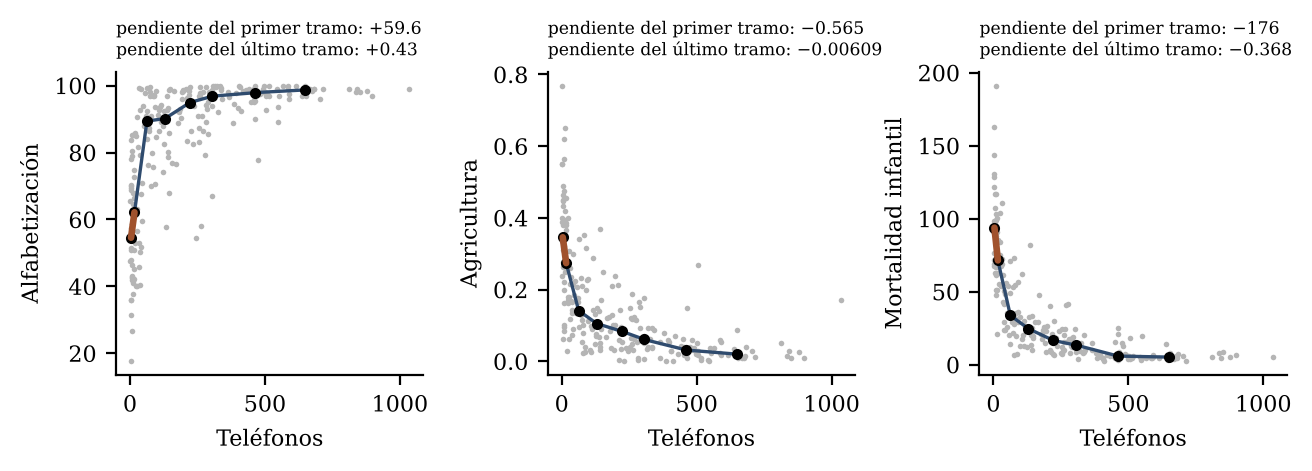

**Cambio de cada variable por cada 100 teléfonos, tramo por tramo**

,Alfabetización,Agricultura,Mortalidad infantil
tramo 1,59.608,-0.565,-175.569
tramo 2,59.047,-0.287,-81.658
tramo 3,1.124,-0.054,-13.621
tramo 4,5.192,-0.023,-8.729
tramo 5,2.271,-0.027,-3.784
tramo 6,0.674,-0.019,-4.846
tramo 7,0.430,-0.006,-0.368


In [23]:
H2_VARS = ["Literacy (%)", "Agriculture", "Infant mortality (per 1000 births)"]
x_h2 = "Phones (per 1000)"
evidencia_h2 = {}
fig, axes = plt.subplots(1, len(H2_VARS), figsize=(6.6, 2.4))
for ax, v in zip(axes, H2_VARS):
    xn, yn = nodos(datos[x_h2], datos[v])
    pend = 100 * np.diff(yn) / np.diff(xn)                     # cambio por cada 100 teléfonos en cada tramo
    evidencia_h2[v] = {"nodos": [[float(a_), float(b_)] for a_, b_ in zip(xn, yn)], "pendientes": pend.tolist(),
                       "r": float(datos[[x_h2, v]].corr().iloc[0, 1]),
                       "spearman": float(datos[[x_h2, v]].corr(method="spearman").iloc[0, 1])}
    xs = np.linspace(xn[0], xn[-1], 300)
    ax.scatter(datos[x_h2], datos[v], s=4, color="#b5b5b5", linewidths=0)
    ax.plot(xs, interpolar(xn, yn, xs), color=C1, lw=1.2)
    ax.plot(xn, yn, "o", color="black", ms=3)
    ax.plot(xn[:2], yn[:2], color=C2, lw=2.4, solid_capstyle="round", label="primer tramo")
    ax.set_xlabel(NOMBRES[x_h2]); ax.set_ylabel(NOMBRES[v])
    ax.set_title(f"pendiente del primer tramo: {pend[0]:+.3g}\npendiente del último tramo: {pend[-1]:+.3g}"
                 .replace("-", "−"), loc="left", fontsize=6.2)
fig.tight_layout(); guardar(fig, "fig_rendimientos.png")
mostrar(pd.DataFrame({NOMBRES[v]: e["pendientes"] for v, e in evidencia_h2.items()},
                     index=[f"tramo {j + 1}" for j in range(len(evidencia_h2[H2_VARS[0]]["pendientes"]))]).round(3),
        "Cambio de cada variable por cada 100 teléfonos, tramo por tramo")
RESULTADOS["evidencia_h2"] = evidencia_h2

## Resultados para el reporte
Se guardan las bases depurada y transformada y todos los números que usa `generar_pdf_reporte.py`.

In [24]:
datos.to_csv(RES / "base_depurada.csv", encoding="utf-8")
trans.to_csv(RES / "base_transformada.csv", encoding="utf-8")
RESULTADOS["VARS"] = VARS
RESULTADOS["NOMBRES"] = NOMBRES
with open(RES / "resultados.json", "w", encoding="utf-8") as f:
    json.dump(RESULTADOS, f, ensure_ascii=False, indent=1, default=float)
print("Listo: gráficas en", FIG.name, "y resultados en", RES.name)

Listo: gráficas en graficas y resultados en resultados
